# Londoni időjárás: leíró statisztikák és feltáró elemzés

Ez a jelentés a nyolc kiválasztott londoni helyszín 2017 és 2023 közötti napi megfigyeléseit mutatja be. Prediktív modelleket nem illeszt. A notebook újrafuttatásakor minden táblázat és ábra újragenerálódik; a forrásként használt CSV-fájl változatlan marad.

In [1]:
from pathlib import Path
import hashlib
import json
import random
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import chi2_contingency, gaussian_kde, kruskal, norm
from IPython.display import display, Markdown

# Reproducible inputs and outputs.
DATA_FILE = "selected_8_places_2017_2023.csv"
OUTPUT_DIR_NAME = "eda_london"
FIGURES_NAME = "figures"
TABLES_NAME = "tables"
LANG = "hu"
RAIN_THRESHOLD_MM = 1.0
RAIN_THRESHOLDS_MM = [0.1, 0.5, 1, 2, 5, 10]
RANDOM_SEED = 2026
FIGURE_DPI = 300
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

PATH_CANDIDATES = [
    Path("projekt") / DATA_FILE,
    Path(DATA_FILE),
    Path("..") / DATA_FILE,
    Path("..") / "projekt" / DATA_FILE,
]
DATA_PATH = next((path.resolve() for path in PATH_CANDIDATES if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Could not find {DATA_FILE!r} in: {PATH_CANDIDATES}")
PROJECT_DIR = DATA_PATH.parent
OUTPUT_DIR = PROJECT_DIR / OUTPUT_DIR_NAME
FIGURES_DIR = OUTPUT_DIR / FIGURES_NAME
TABLES_DIR = OUTPUT_DIR / TABLES_NAME
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_README = OUTPUT_DIR / "README.md"

# One switch controls all figure titles, axes, legends, and summary labels.
TEXT = {
    "hu": {
        "min_temp": "Minimum-hőmérséklet", "max_temp": "Maximum-hőmérséklet",
        "rain": "Csapadék", "humidity": "Páratartalom", "cloud_cover": "Felhőborítottság",
        "wind_speed": "Szélsebesség", "wind_direction_numerical": "Szélirány (fok)",
        "temp_range": "Napi hőmérsékleti terjedelem",
        "date": "Dátum", "location": "Helyszín", "year": "Év", "month": "Hónap",
        "frequency": "Gyakoriság", "density": "Sűrűség", "count": "Megfigyelések száma",
        "mean": "Átlag", "rain_share": "Esős napok aránya",
        "rain_amount": "Csapadék (mm)", "temperature": "Hőmérséklet (°C)",
        "humidity_axis": "Páratartalom (%)", "cloud_axis": "Felhőborítottság (%)",
        "wind_speed_axis": "Szélsebesség (km/h)", "direction_axis": "Irány",
        "mean_rain": "Átlagos csapadék (mm)", "share_axis": "Arány",
        "residual": "Megfigyelt érték", "rain_tomorrow": "Eső másnap",
        "today_rain": "Eső ma", "probability": "Másnapi eső aránya",
        "pooled_mean": "Teljes időszak átlaga", "rolling": "12 havi gördülő átlag",
        "monthly_mean": "Havi átlag", "monthly_total": "Havi összeg",
        "corr_pearson": "Pearson-korreláció", "corr_spearman": "Spearman-korreláció",
        "rainy_frequency": "Szélirány gyakorisága", "rainy_mean": "Átlagos eső irány szerint",
        "ci_title_location": "Legalább 1 mm-es napok aránya helyszínenként",
        "ci_title_year": "Legalább 1 mm-es napok aránya évenként",
        "acf": "Autokorreláció", "lag": "Késleltetés (nap)",
        "outcome": "Másnapi kimenet", "share": "Sorarány",
        "by_location": "Helyszínenként", "by_year": "Évenként",
        "by_month": "Naptári hónap szerint", "distribution": "Eloszlás",
        "hist_title": "Eloszlás: {name}", "box_location": "Eloszlás helyszínenként: {name}",
        "box_month": "Eloszlás naptári hónap szerint: {name}",
        "monthly_clim": "Havi klimatológia: {name}",
        "series_title": "Havi idősor: {name}",
        "rain_heatmap": "Átlagos csapadék naptári hónap és év szerint",
        "location_heatmap": "Átlagos csapadék helyszín és naptári hónap szerint",
        "scatter_title": "{x} és {y}",
        "direction_freq": "Szélirány-gyakoriság",
        "direction_rain": "Csapadék szélirány szerint",
        "monthly_rain_total": "Havi csapadékösszeg (mm)",
        "monthly_wet_share": "Legalább 1 mm-es napok aránya",
        "acfs_title": "Napi autokorreláció (max. 30 nap)",
        "single_site": "Egy helyszín", "site_average": "8 helyszín napi átlaga",
        "decile": "Decilis", "target_share": "Másnapi eső aránya",
        "wilson_low": "95%-os CI alsó határa", "wilson_high": "95%-os CI felső határa",
        "rain_direction_note": "A jelölő a 100-nál kevesebb megfigyelésű irányt jelzi.",
        "rain_symlog_note": "Az esős napok csapadéka; szimmetrikus log (symlog) tengely.",
        "degree_note": "A fokban mért szélirány körkörös változó; lineáris statisztikái csak tájékoztatók.",
        "month_names": ["Jan", "Feb", "Már", "Ápr", "Máj", "Jún", "Júl", "Aug", "Szep", "Okt", "Nov", "Dec"],
        "N": "É", "NNE": "ÉÉK", "NE": "ÉK", "ENE": "KÉK",
        "E": "K", "ESE": "KDK", "SE": "DK", "SSE": "DDK",
        "S": "D", "SSW": "DDNy", "SW": "DNy", "WSW": "NyDNy",
        "W": "Ny", "WNW": "NyÉNy", "NW": "ÉNy", "NNW": "ÉÉNy",
    },
    "en": {
        "min_temp": "Minimum temperature", "max_temp": "Maximum temperature",
        "rain": "Rain", "humidity": "Humidity", "cloud_cover": "Cloud cover",
        "wind_speed": "Wind speed", "wind_direction_numerical": "Wind direction (degrees)",
        "temp_range": "Daily temperature range",
        "date": "Date", "location": "Location", "year": "Year", "month": "Month",
        "frequency": "Frequency", "density": "Density", "count": "Observations",
        "mean": "Mean", "rain_share": "Share of rainy days",
        "rain_amount": "Rain (mm)", "temperature": "Temperature (°C)",
        "humidity_axis": "Humidity (%)", "cloud_axis": "Cloud cover (%)",
        "wind_speed_axis": "Wind speed (km/h)", "direction_axis": "Direction",
        "mean_rain": "Mean rain (mm)", "share_axis": "Share",
        "residual": "Observed value", "rain_tomorrow": "Rain tomorrow",
        "today_rain": "Rain today", "probability": "Share with rain tomorrow",
        "pooled_mean": "Pooled period mean", "rolling": "12-month rolling mean",
        "monthly_mean": "Monthly mean", "monthly_total": "Monthly total",
        "corr_pearson": "Pearson correlation", "corr_spearman": "Spearman correlation",
        "rainy_frequency": "Frequency by wind direction", "rainy_mean": "Mean rain by direction",
        "ci_title_location": "Share of days with at least 1 mm rain by location",
        "ci_title_year": "Share of days with at least 1 mm rain by year",
        "acf": "Autocorrelation", "lag": "Lag (days)",
        "outcome": "Next-day outcome", "share": "Row share",
        "by_location": "By location", "by_year": "By year",
        "by_month": "By calendar month", "distribution": "Distribution",
        "hist_title": "Distribution: {name}", "box_location": "Distribution by location: {name}",
        "box_month": "Distribution by calendar month: {name}",
        "monthly_clim": "Monthly climatology: {name}",
        "series_title": "Monthly time series: {name}",
        "rain_heatmap": "Mean rain by calendar month and year",
        "location_heatmap": "Mean rain by location and calendar month",
        "scatter_title": "{x} and {y}",
        "direction_freq": "Wind direction frequency",
        "direction_rain": "Rain by wind direction",
        "monthly_rain_total": "Monthly rain total (mm)",
        "monthly_wet_share": "Share of days with at least 1 mm rain",
        "acfs_title": "Daily autocorrelation (up to 30 days)",
        "single_site": "One location", "site_average": "Daily average across 8 locations",
        "decile": "Decile", "target_share": "Share with rain tomorrow",
        "wilson_low": "95% CI lower", "wilson_high": "95% CI upper",
        "rain_direction_note": "Markers identify directions with fewer than 100 observations.",
        "rain_symlog_note": "Rain on wet days; symmetric log (symlog) axis.",
        "degree_note": "Wind direction in degrees is circular; linear summaries are indicative only.",
        "month_names": ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        "N": "N", "NE": "NE", "E": "E", "SE": "SE", "S": "S", "SW": "SW", "W": "W", "NW": "NW",
    },
}
if LANG not in TEXT:
    raise ValueError(f"Unsupported LANG={LANG!r}; choose from {list(TEXT)}")
T = TEXT[LANG]

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": FIGURE_DPI, "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 10,
    "ytick.labelsize": 10, "legend.fontsize": 10, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
})
PALETTE = plt.get_cmap("tab10").colors
COMPASS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
           "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]

raw = pd.read_csv(DATA_PATH)
units = {}
rename = {}
for original in raw.columns:
    normalized = original.split(" ", 1)[0].strip().lower()
    rename[original] = normalized
    units[normalized] = original.split(" ", 1)[1].strip() if " " in original else ""
df = raw.rename(columns=rename).copy()
if "wind_direction_numerical" in df:
    units["wind_direction_numerical"] = "degrees"
df["date"] = pd.to_datetime(df["date"], errors="raise")
df = df.sort_values(["location", "date"]).reset_index(drop=True)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_start"] = df["date"].dt.to_period("M").dt.to_timestamp()
df["temp_range"] = df["max_temp"] - df["min_temp"]
NUMERIC_VARS = [
    "min_temp", "max_temp", "rain", "humidity", "cloud_cover",
    "wind_speed", "wind_direction_numerical", "temp_range",
]
NUMERIC_LABELS = {
    "min_temp": "Minimum-hőmérséklet (°C)",
    "max_temp": "Maximum-hőmérséklet (°C)",
    "rain": "Csapadék (mm)",
    "humidity": "Páratartalom (%)",
    "cloud_cover": "Felhőborítottság (%)",
    "wind_speed": "Szélsebesség (km/h)",
    "wind_direction_numerical": "Szélirány (fok)",
    "temp_range": "Napi hőmérsékleti terjedelem (°C)",
}
if LANG == "en":
    NUMERIC_LABELS = {
        "min_temp": "Minimum temperature (°C)", "max_temp": "Maximum temperature (°C)",
        "rain": "Rain (mm)", "humidity": "Humidity (%)", "cloud_cover": "Cloud cover (%)",
        "wind_speed": "Wind speed (km/h)", "wind_direction_numerical": "Wind direction (degrees)",
        "temp_range": "Daily temperature range (°C)",
    }

def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=FIGURE_DPI, bbox_inches="tight")
    display(fig)
    plt.close(fig)

def save_table(table, filename, index=False):
    table.to_csv(TABLES_DIR / filename, index=index, encoding="utf-8-sig")
    display(table)

def pct(value):
    return f"{100 * value:,.1f}%"

print(f"A bet\u00f6lt\u00f6tt adatok m\u00e9rete: {len(df):,} sor \u00d7 {len(raw.columns):,} nyers oszlop ({DATA_PATH.name}).")
print(f"Normaliz\u00e1lt oszlopok: {list(df.columns)}")
print(f"Felismert m\u00e9rt\u00e9kegys\u00e9gek: {units}")


A betöltött adatok mérete: 20,440 sor × 10 nyers oszlop (selected_8_places_2017_2023.csv).
Normalizált oszlopok: ['location', 'date', 'min_temp', 'max_temp', 'rain', 'humidity', 'cloud_cover', 'wind_speed', 'wind_direction', 'wind_direction_numerical', 'year', 'month', 'month_start', 'temp_range']
Felismert mértékegységek: {'location': '', 'date': '', 'min_temp': '°c', 'max_temp': '°c', 'rain': 'mm', 'humidity': '%', 'cloud_cover': '%', 'wind_speed': 'km/h', 'wind_direction': '', 'wind_direction_numerical': 'degrees'}


## 1. Adataudit

In [2]:
location_order = sorted(df["location"].unique())
date_min, date_max = df["date"].min(), df["date"].max()
calendar = pd.date_range(date_min, date_max, freq="D")
missing_day_rows = []
for location, group in df.groupby("location", sort=True):
    observed_dates = pd.DatetimeIndex(group["date"].unique())
    missing_dates = calendar.difference(observed_dates)
    missing_day_rows.append({
        "location": location, "observed_days": len(observed_dates),
        "expected_days": len(calendar), "missing_calendar_days": len(missing_dates),
        "missing_dates": "; ".join(d.strftime("%Y-%m-%d") for d in missing_dates),
    })
missing_days = pd.DataFrame(missing_day_rows)

audit_summary = pd.DataFrame([
    {"check": "Rows", "value": len(df)},
    {"check": "Locations", "value": df["location"].nunique()},
    {"check": "Date start", "value": date_min.strftime("%Y-%m-%d")},
    {"check": "Date end", "value": date_max.strftime("%Y-%m-%d")},
    {"check": "Exact duplicate rows", "value": int(df.duplicated().sum())},
    {"check": "Duplicate (location, date) pairs", "value": int(df.duplicated(["location", "date"]).sum())},
    {"check": "Missing values (all columns)", "value": int(df.isna().sum().sum())},
])
print("Méret, dátumtartomány, duplikátumok, hiányzó értékek ellenőrzése:")
save_table(audit_summary, "data_audit_summary.csv")
print("Adatt\u00edpusok normaliz\u00e1l\u00e1s ut\u00e1n:")
display(df[["location", "date", *NUMERIC_VARS[:-1]]].dtypes.rename("dtype").to_frame())
print("Sorok helysz\u00ednenk\u00e9nt:")
rows_by_location = df.groupby("location").size().rename("rows").reset_index()
save_table(rows_by_location, "rows_by_location.csv")
print("Napt\u00e1ri lefedetts\u00e9g helysz\u00ednenk\u00e9nt:")
save_table(missing_days, "missing_calendar_days.csv")
print("Hiányzó értékek oszloponként:")
missing_by_column = pd.DataFrame({
    "column": df.columns,
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_share": [float(df[c].isna().mean()) for c in df.columns],
})
save_table(missing_by_column, "missing_values.csv")

violations = []
range_checks = [
    ("humidity", df["humidity"].lt(0) | df["humidity"].gt(100), "Expected range 0–100%"),
    ("cloud_cover", df["cloud_cover"].lt(0) | df["cloud_cover"].gt(100), "Expected range 0–100%"),
    ("min_temp <= max_temp", df["min_temp"].gt(df["max_temp"]), "Minimum exceeds maximum"),
    ("rain", df["rain"].lt(0), "Negative rainfall"),
    ("wind_speed", df["wind_speed"].lt(0), "Negative wind speed"),
    ("wind_direction_numerical", df["wind_direction_numerical"].lt(0) | df["wind_direction_numerical"].ge(360), "Expected degrees in [0, 360)"),
]
for variable, mask, rule in range_checks:
    violations.append({
        "variable": variable, "rule": rule, "violations": int(mask.sum()),
        "share": float(mask.mean()),
    })
violations = pd.DataFrame(violations)
print("\u00c9rt\u00e9ktartom\u00e1nyok ellen\u0151rz\u00e9se:")
save_table(violations, "range_violations.csv")

numeric_hashes = []
for location, group in df.groupby("location", sort=True):
    values = group[NUMERIC_VARS[:-1]].to_numpy(dtype=np.float64)
    digest = hashlib.sha256(values.tobytes()).hexdigest()
    numeric_hashes.append({"location": location, "numeric_series_sha256": digest})
numeric_hashes = pd.DataFrame(numeric_hashes)
print(f"A h\u00e9t nyers numerikus oszlop alapj\u00e1n k\u00fcl\u00f6nb\u00f6z\u0151 id\u0151sor-azonos\u00edt\u00f3k sz\u00e1ma: {numeric_hashes['numeric_series_sha256'].nunique()} / {len(numeric_hashes)}.")
save_table(numeric_hashes, "location_series_hashes.csv")
rain_wide = df.pivot(index="date", columns="location", values="rain").reindex(columns=location_order)
rain_differences = pd.DataFrame(index=location_order, columns=location_order, dtype="int64")
for left in location_order:
    for right in location_order:
        rain_differences.loc[left, right] = int(rain_wide[left].ne(rain_wide[right]).sum())
rain_differences.index.name = "location"
print("Az elt\u00e9r\u0151 napi csapad\u00e9k\u00fa d\u00e1tumok p\u00e1ronk\u00e9nti sz\u00e1ma:")
save_table(rain_differences.reset_index(), "pairwise_rain_differences.csv")

feb29_missing_all = bool(
    pd.Timestamp("2020-02-29") in calendar
    and missing_days["missing_dates"].str.contains("2020-02-29", regex=False).all()
)
display(Markdown(
    f"Az adataudit szerint **{df['location'].nunique()} helyszínhez** egyenként "
    f"{int(rows_by_location['rows'].min()):,}–{int(rows_by_location['rows'].max()):,} sor tartozik; pontos duplikált sorok száma "
    f"{int(df.duplicated().sum())}, ismétlődő helyszín-dátum kulcs nincs. "
    f"A 2020-02-29-i nap mind a nyolc helyszínnél hiányzik ({feb29_missing_all}), nem interpoláltuk. "
    f"Mind a {numeric_hashes['numeric_series_sha256'].nunique()} numerikus idősor különböző; "
    f"a leginkább hasonló csapadék-idősorok is "
    f"{int(rain_differences.where(~np.eye(len(location_order), dtype=bool)).min().min()):,} megfigyelt napon térnek el egymástól."

))


Méret, dátumtartomány, duplikátumok, hiányzó értékek ellenőrzése:


,check,value
0,Rows,20440
1,Locations,8
2,Date start,2017-01-01
3,Date end,2023-12-31
4,Exact duplicate rows,0
5,"Duplicate (location, date) pairs",0
6,Missing values (all columns),0


Adattípusok normalizálás után:


,dtype
location,str
date,datetime64[us]
min_temp,float64
max_temp,float64
rain,float64
humidity,float64
cloud_cover,float64
wind_speed,float64
wind_direction_numerical,float64


Sorok helyszínenként:


,location,rows
0,Barnehurst,2555
1,Barnsbury,2555
2,Bexleyheath,2555
3,Blackfen,2555
4,Furzedown,2555
5,Knight's Hill,2555
6,Lessness Heath,2555
7,Park Lane,2555


... (7 outputs left out)

,location,numeric_series_sha256
0,Barnehurst,bc8c20b165b6ee9104a7967cbdb02960840144b23b53f7...
1,Barnsbury,9801da052cefee8b660b8361259b62afe00bae6144256c...
2,Bexleyheath,e80e1d736c064a65c9ba6012e4402ab2fa368b598d103f...
3,Blackfen,4c744a27253ffd3731a02ff25062ecec9c0f9ae46f34e3...
4,Furzedown,d769af60c6172506ed5ea22ee825a3c21c314cb1407cd3...
5,Knight's Hill,4f3aff658c34d43c1bcb15982772612c1b1ba9dda82e67...
6,Lessness Heath,11294cf544a6d0015b86d9eea1bfacc80c699eb2266361...
7,Park Lane,911a3d1971290deba05813c4b15501674ac8192a66deba...


Az eltérő napi csapadékú dátumok páronkénti száma:


,location,Barnehurst,Barnsbury,Bexleyheath,Blackfen,Furzedown,Knight's Hill,Lessness Heath,Park Lane
0,Barnehurst,0.0,1344.0,1346.0,1342.0,1452.0,1429.0,225.0,1824.0
1,Barnsbury,1344.0,0.0,246.0,254.0,1423.0,1294.0,1350.0,1824.0
2,Bexleyheath,1346.0,246.0,0.0,234.0,1422.0,1346.0,1336.0,1825.0
3,Blackfen,1342.0,254.0,234.0,0.0,1407.0,1356.0,1339.0,1823.0
4,Furzedown,1452.0,1423.0,1422.0,1407.0,0.0,1441.0,1450.0,1838.0
5,Knight's Hill,1429.0,1294.0,1346.0,1356.0,1441.0,0.0,1430.0,1807.0
6,Lessness Heath,225.0,1350.0,1336.0,1339.0,1450.0,1430.0,0.0,1824.0
7,Park Lane,1824.0,1824.0,1825.0,1823.0,1838.0,1807.0,1824.0,0.0


Az adataudit szerint **8 helyszínhez** egyenként 2,555–2,555 sor tartozik; pontos duplikált sorok száma 0, ismétlődő helyszín-dátum kulcs nincs. A 2020-02-29-i nap mind a nyolc helyszínnél hiányzik (True), nem interpoláltuk. Mind a 8 numerikus idősor különböző; a leginkább hasonló csapadék-idősorok is 225 megfigyelt napon térnek el egymástól.

## 2. Leíró statisztikák

In [3]:
def describe_numeric(group, variable):
    series = pd.to_numeric(group[variable], errors="coerce").dropna()
    if series.empty:
        return {"n": 0}
    q05, q25, q50, q75, q95 = series.quantile([.05, .25, .50, .75, .95]).to_numpy()
    iqr = q75 - q25
    lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    return {
        "n": int(series.size), "mean": float(series.mean()), "std": float(series.std()),
        "min": float(series.min()), "p05": float(q05), "p25": float(q25),
        "p50": float(q50), "p75": float(q75), "p95": float(q95),
        "max": float(series.max()), "skewness": float(series.skew()),
        "kurtosis": float(series.kurt()), "iqr": float(iqr),
        "share_zeros": float(series.eq(0).mean()) if variable == "rain" else np.nan,
        "outliers_1_5iqr": int(series.lt(lower).sum() + series.gt(upper).sum()),
    }

def stats_table(data, by=None):
    records = []
    grouped = [((), data)] if by is None else data.groupby(by, observed=True, sort=True)
    for key, group in grouped:
        key = key if isinstance(key, tuple) else (key,)
        for variable in NUMERIC_VARS:
            row = dict(zip(by or [], key))
            row["variable"] = variable
            row.update(describe_numeric(group, variable))
            records.append(row)
    return pd.DataFrame(records)

stats_overall = stats_table(df)
stats_location = stats_table(df, ["location"])
stats_year = stats_table(df, ["year"])
stats_month = stats_table(df, ["month"])
print("Összesített leíró statisztikák (a szögadatok körkörűek; lineáris összegzéseik csak tájékoztató jellegűek):")
save_table(stats_overall.round(4), "descriptive_overall.csv")
print("Le\u00edr\u00f3 statisztik\u00e1k helysz\u00ednenk\u00e9nt:")
save_table(stats_location.round(4), "descriptive_by_location.csv")
print("Leíró statisztikák évenként:")
save_table(stats_year.round(4), "descriptive_by_year.csv")
print("Leíró statisztikák naptári hónap szerint, az éveket összevonva:")
save_table(stats_month.round(4), "descriptive_by_calendar_month.csv")

direction_table = (
    df["wind_direction"].value_counts().reindex(COMPASS, fill_value=0)
    .rename_axis("wind_direction").rename("count").to_frame()
)
direction_table["relative_frequency"] = direction_table["count"] / len(df)
print("Szélirányok darabszáma és relatív gyakorisága (mind a 16 égtáj):")
save_table(direction_table.reset_index().round(5), "wind_direction_frequency.csv")

rain_threshold_rows = []
for threshold in RAIN_THRESHOLDS_MM:
    rain_threshold_rows.append({
        "threshold_mm": threshold,
        "days_at_or_above": int(df["rain"].ge(threshold).sum()),
        "share_at_or_above": float(df["rain"].ge(threshold).mean()),
    })
rain_threshold_table = pd.DataFrame(rain_threshold_rows)
rainy_days = df.loc[df["rain"].ge(RAIN_THRESHOLD_MM), "rain"]
rain_summary = pd.DataFrame([{
    "rainy_day_threshold_mm": RAIN_THRESHOLD_MM,
    "share_days_rain_ge_0_1": float(df["rain"].ge(.1).mean()),
    "share_days_rain_ge_1": float(df["rain"].ge(1).mean()),
    "share_days_rain_ge_5": float(df["rain"].ge(5).mean()),
    "share_days_rain_ge_10": float(df["rain"].ge(10).mean()),
    "mean_rain_on_days_ge_1_mm": float(rainy_days.mean()),
    "median_rain_on_days_ge_1_mm": float(rainy_days.median()),
    "zero_rain_share": float(df["rain"].eq(0).mean()),
}])
print("Csapadékküszöbök szerinti érzékenység és csapadékos napok összegzése:")
save_table(rain_threshold_table.round(4), "rain_threshold_sensitivity.csv")
save_table(rain_summary.round(4), "rain_summary.csv")

def longest_spell(group, wet):
    group = group.sort_values("date")
    condition = group["rain"].ge(RAIN_THRESHOLD_MM) if wet else group["rain"].lt(RAIN_THRESHOLD_MM)
    best_length, best_start, best_end = 0, None, None
    current_length, current_start, previous_date = 0, None, None
    for date, matches in zip(group["date"], condition):
        consecutive = previous_date is not None and (date - previous_date).days == 1
        if matches and (current_length == 0 or consecutive):
            if current_length == 0:
                current_start = date
            current_length += 1
        elif matches:
            current_length, current_start = 1, date
        else:
            current_length, current_start = 0, None
        if current_length > best_length:
            best_length, best_start, best_end = current_length, current_start, date
        previous_date = date
    return best_length, best_start, best_end

spell_rows = []
for location, group in df.groupby("location", sort=True):
    for kind, wet in [("dry_lt_1mm", False), ("wet_ge_1mm", True)]:
        length, start, end = longest_spell(group, wet)
        spell_rows.append({
            "location": location, "spell": kind, "threshold_mm": RAIN_THRESHOLD_MM,
            "longest_consecutive_days": length,
            "start": start.strftime("%Y-%m-%d") if start is not None else "",
            "end": end.strftime("%Y-%m-%d") if end is not None else "",
        })
spell_table = pd.DataFrame(spell_rows)
print("Leghosszabb száraz (<1 mm) és csapadékos (>=1 mm) időszakok; a naptári hiány megszakítja az időszakot:")
save_table(spell_table, "rain_spells_by_location.csv")
display(Markdown(
    f"A **{len(df):,} megfigyelésben** a napi hőmérsékleti terjedelem átlaga "
    f"**{df['temp_range'].mean():.2f} °C**; a sorok **{pct(df['rain'].ge(1).mean())}**-án legalább 1 mm eső esett, "
    f"a csapadékos napok mediánja **{rainy_days.median():.2f} mm**. A leghosszabb száraz időszak "
    f"**{int(spell_table.loc[spell_table.spell.eq('dry_lt_1mm'), 'longest_consecutive_days'].max())} napos**; "
    f"a leghosszabb csapadékos időszak pedig **{int(spell_table.loc[spell_table.spell.eq('wet_ge_1mm'), 'longest_consecutive_days'].max())} napos**."

))


Összesített leíró statisztikák (a szögadatok körkörűek; lineáris összegzéseik csak tájékoztató jellegűek):


,variable,n,mean,std,min,p05,p25,p50,p75,p95,max,skewness,kurtosis,iqr,share_zeros,outliers_1_5iqr
0,min_temp,20440,8.5204,5.0617,-7.0,0.0,5.0,8.0,13.0,17.000,25.0,0.0297,-0.6574,8.0,NaN,0
1,max_temp,20440,15.0175,6.3489,-2.0,5.0,10.0,14.0,20.0,25.000,40.0,0.2429,-0.4324,10.0,NaN,19
2,rain,20440,2.1224,4.1362,0.0,0.0,0.0,0.2,2.4,10.305,50.3,3.4845,17.0604,2.4,0.4314,2384
3,humidity,20440,74.3292,10.9656,19.0,55.0,67.0,75.0,83.0,90.000,100.0,-0.4301,-0.0500,16.0,NaN,75
4,cloud_cover,20440,53.9623,26.4748,0.0,7.0,34.0,56.0,75.0,94.000,100.0,-0.2293,-0.9202,41.0,NaN,0
5,wind_speed,20440,14.2838,6.0955,1.0,6.0,10.0,13.0,18.0,26.000,46.0,0.7204,0.4670,8.0,NaN,238
6,wind_direction_numerical,20440,197.6477,76.6902,0.0,45.0,157.5,225.0,247.5,292.500,337.5,-0.5954,-0.5254,90.0,NaN,17
7,temp_range,20440,6.4971,2.6994,1.0,3.0,4.0,6.0,8.0,11.000,19.0,0.5154,0.0085,4.0,NaN,89


Leíró statisztikák helyszínenként:


,location,variable,n,mean,std,min,p05,p25,p50,p75,p95,max,skewness,kurtosis,iqr,share_zeros,outliers_1_5iqr
0,Barnehurst,min_temp,2555,8.7980,5.0113,-5.0,1.0,5.0,9.0,13.0,17.0,24.0,0.0226,-0.7076,8.0,NaN,0
1,Barnehurst,max_temp,2555,15.1370,6.3141,-2.0,5.0,10.0,14.0,20.0,25.0,39.0,0.1836,-0.5365,10.0,NaN,2
2,Barnehurst,rain,2555,2.0173,4.0356,0.0,0.0,0.0,0.2,2.2,9.8,35.9,3.5272,16.6940,2.2,0.4446,310
3,Barnehurst,humidity,2555,74.3773,9.9176,21.0,58.0,67.0,75.0,82.0,89.0,97.0,-0.3772,0.1666,15.0,NaN,8
4,Barnehurst,cloud_cover,2555,52.3890,26.4402,0.0,7.0,31.5,54.0,74.0,93.0,100.0,-0.1632,-0.9621,42.5,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,Park Lane,humidity,2555,82.9785,7.1566,39.0,71.0,79.0,83.0,88.0,94.0,100.0,-0.7231,1.8218,9.0,NaN,26
60,Park Lane,cloud_cover,2555,59.9601,24.8418,0.0,13.0,44.0,63.0,80.0,96.0,100.0,-0.4425,-0.5856,36.0,NaN,0
61,Park Lane,wind_speed,2555,13.7229,6.0095,2.0,6.0,9.0,13.0,17.0,25.0,40.0,0.7188,0.3071,8.0,NaN,31
62,Park Lane,wind_direction_numerical,2555,216.1057,62.9455,22.5,112.5,180.0,225.0,270.0,315.0,337.5,-0.3939,-0.0924,90.0,NaN,4


Leíró statisztikák évenként:


,year,variable,n,mean,std,min,p05,p25,p50,p75,p95,max,skewness,kurtosis,iqr,share_zeros,outliers_1_5iqr
0,2017,min_temp,2920,8.2219,4.9508,-3.0,0.0,5.0,8.0,12.0,16.000,19.0,-0.1289,-0.9453,7.0,NaN,0
1,2017,max_temp,2920,14.5134,5.9028,0.0,5.0,10.0,14.0,19.0,24.000,31.0,0.0407,-0.7610,9.0,NaN,0
2,2017,rain,2920,1.8803,3.8255,0.0,0.0,0.0,0.2,1.9,8.815,32.9,3.5347,15.5014,1.9,0.4240,365
3,2017,humidity,2920,79.4832,9.1747,46.0,62.0,74.0,81.0,86.0,92.000,97.0,-0.5806,-0.1687,12.0,NaN,21
4,2017,cloud_cover,2920,55.1161,24.4941,1.0,12.0,37.0,56.0,74.0,94.000,100.0,-0.1570,-0.7723,37.0,NaN,0
5,2017,wind_speed,2920,14.8271,5.8155,2.0,7.0,10.0,14.0,18.0,26.000,39.0,0.5748,0.2656,8.0,NaN,22
6,2017,wind_direction_numerical,2920,217.9803,66.9787,22.5,67.5,180.0,225.0,270.0,315.000,337.5,-0.8203,0.2494,90.0,NaN,21
7,2017,temp_range,2920,6.2914,2.4351,1.0,3.0,5.0,6.0,8.0,11.000,17.0,0.3760,0.1838,3.0,NaN,23
8,2018,min_temp,2920,9.0274,5.4349,-7.0,1.0,5.0,9.0,13.0,18.000,21.0,0.0324,-0.7289,8.0,NaN,0
9,2018,max_temp,2920,15.4479,7.0594,-2.0,5.0,10.0,15.0,21.0,27.000,33.0,0.1431,-0.7880,11.0,NaN,0


... (6 outputs left out)

,rainy_day_threshold_mm,share_days_rain_ge_0_1,share_days_rain_ge_1,share_days_rain_ge_5,share_days_rain_ge_10,mean_rain_on_days_ge_1_mm,median_rain_on_days_ge_1_mm,zero_rain_share
0,1.0,0.5686,0.3658,0.1451,0.0525,5.5869,3.9,0.4314


Leghosszabb száraz (<1 mm) és csapadékos (>=1 mm) időszakok; a naptári hiány megszakítja az időszakot:


,location,spell,threshold_mm,longest_consecutive_days,start,end
0,Barnehurst,dry_lt_1mm,1.0,40,2018-06-17,2018-07-26
1,Barnehurst,wet_ge_1mm,1.0,11,2019-12-12,2019-12-22
2,Barnsbury,dry_lt_1mm,1.0,34,2020-05-02,2020-06-04
3,Barnsbury,wet_ge_1mm,1.0,11,2019-12-12,2019-12-22
4,Bexleyheath,dry_lt_1mm,1.0,34,2020-05-02,2020-06-04
5,Bexleyheath,wet_ge_1mm,1.0,11,2019-12-12,2019-12-22
6,Blackfen,dry_lt_1mm,1.0,34,2020-05-02,2020-06-04
7,Blackfen,wet_ge_1mm,1.0,14,2023-10-23,2023-11-05
8,Furzedown,dry_lt_1mm,1.0,32,2020-03-16,2020-04-16
9,Furzedown,wet_ge_1mm,1.0,14,2023-10-23,2023-11-05


A **20,440 megfigyelésben** a napi hőmérsékleti terjedelem átlaga **6.50 °C**; a sorok **36.6%**-án legalább 1 mm eső esett, a csapadékos napok mediánja **3.90 mm**. A leghosszabb száraz időszak **40 napos**; a leghosszabb csapadékos időszak pedig **18 napos**.

## 3. Ábrák

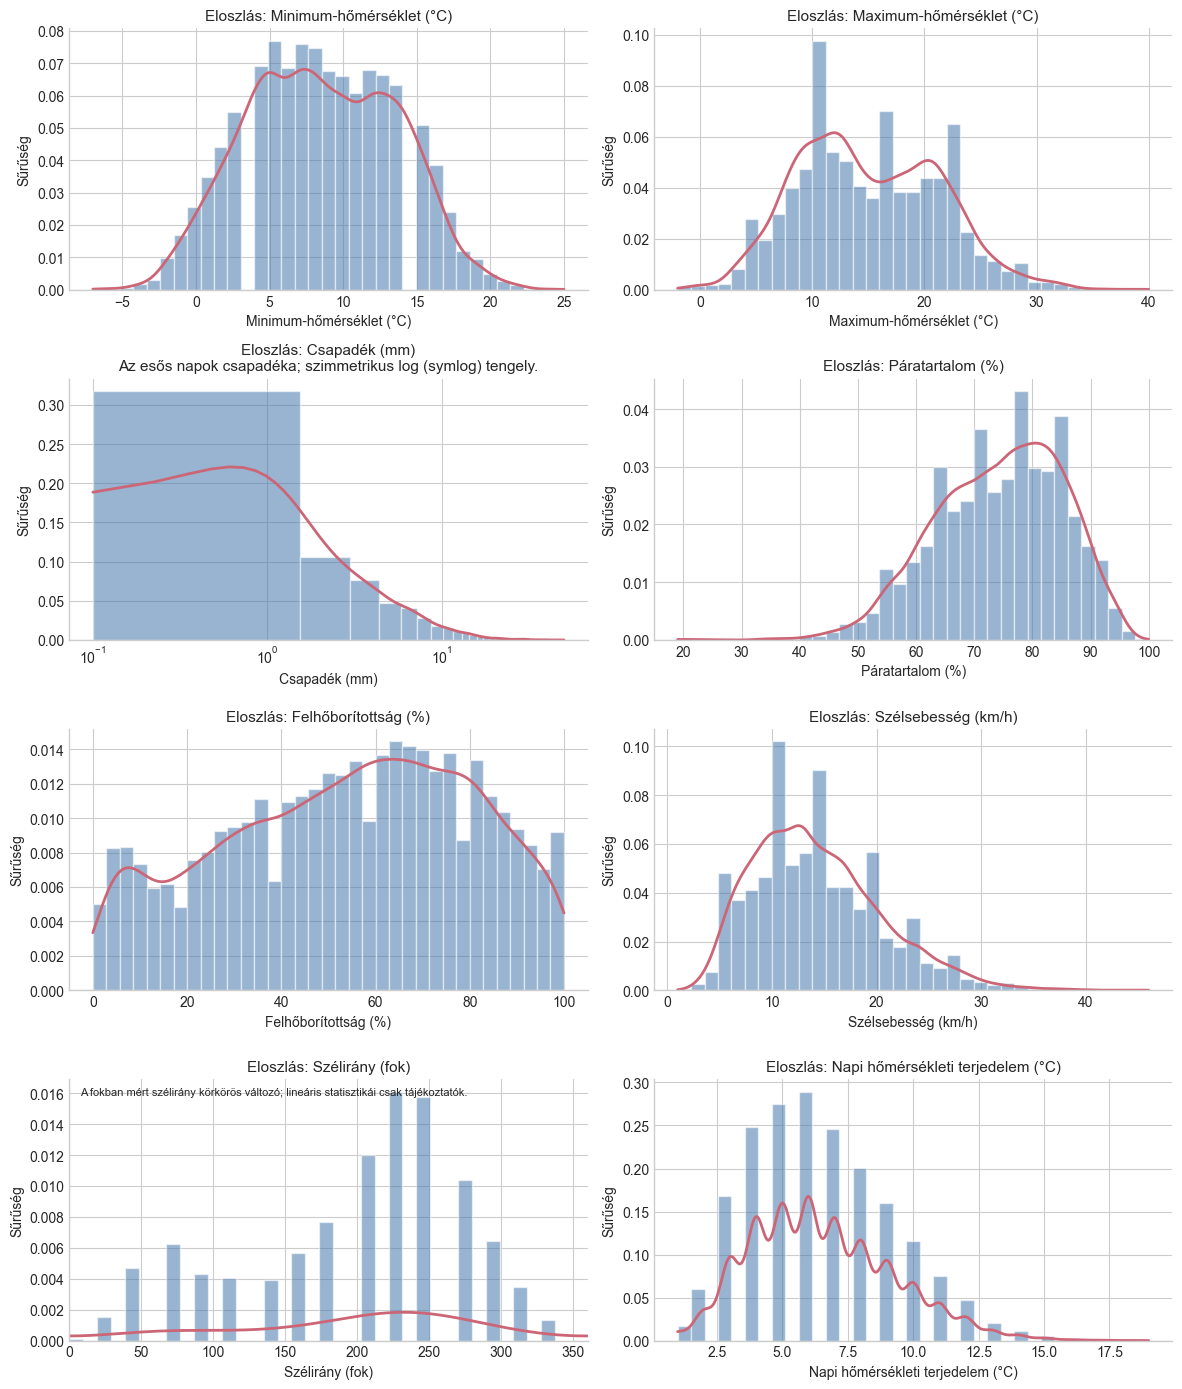

C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=location_order, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=location_order, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=location_order, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23

C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=location_order, showfliers=False, patch_artist=True,


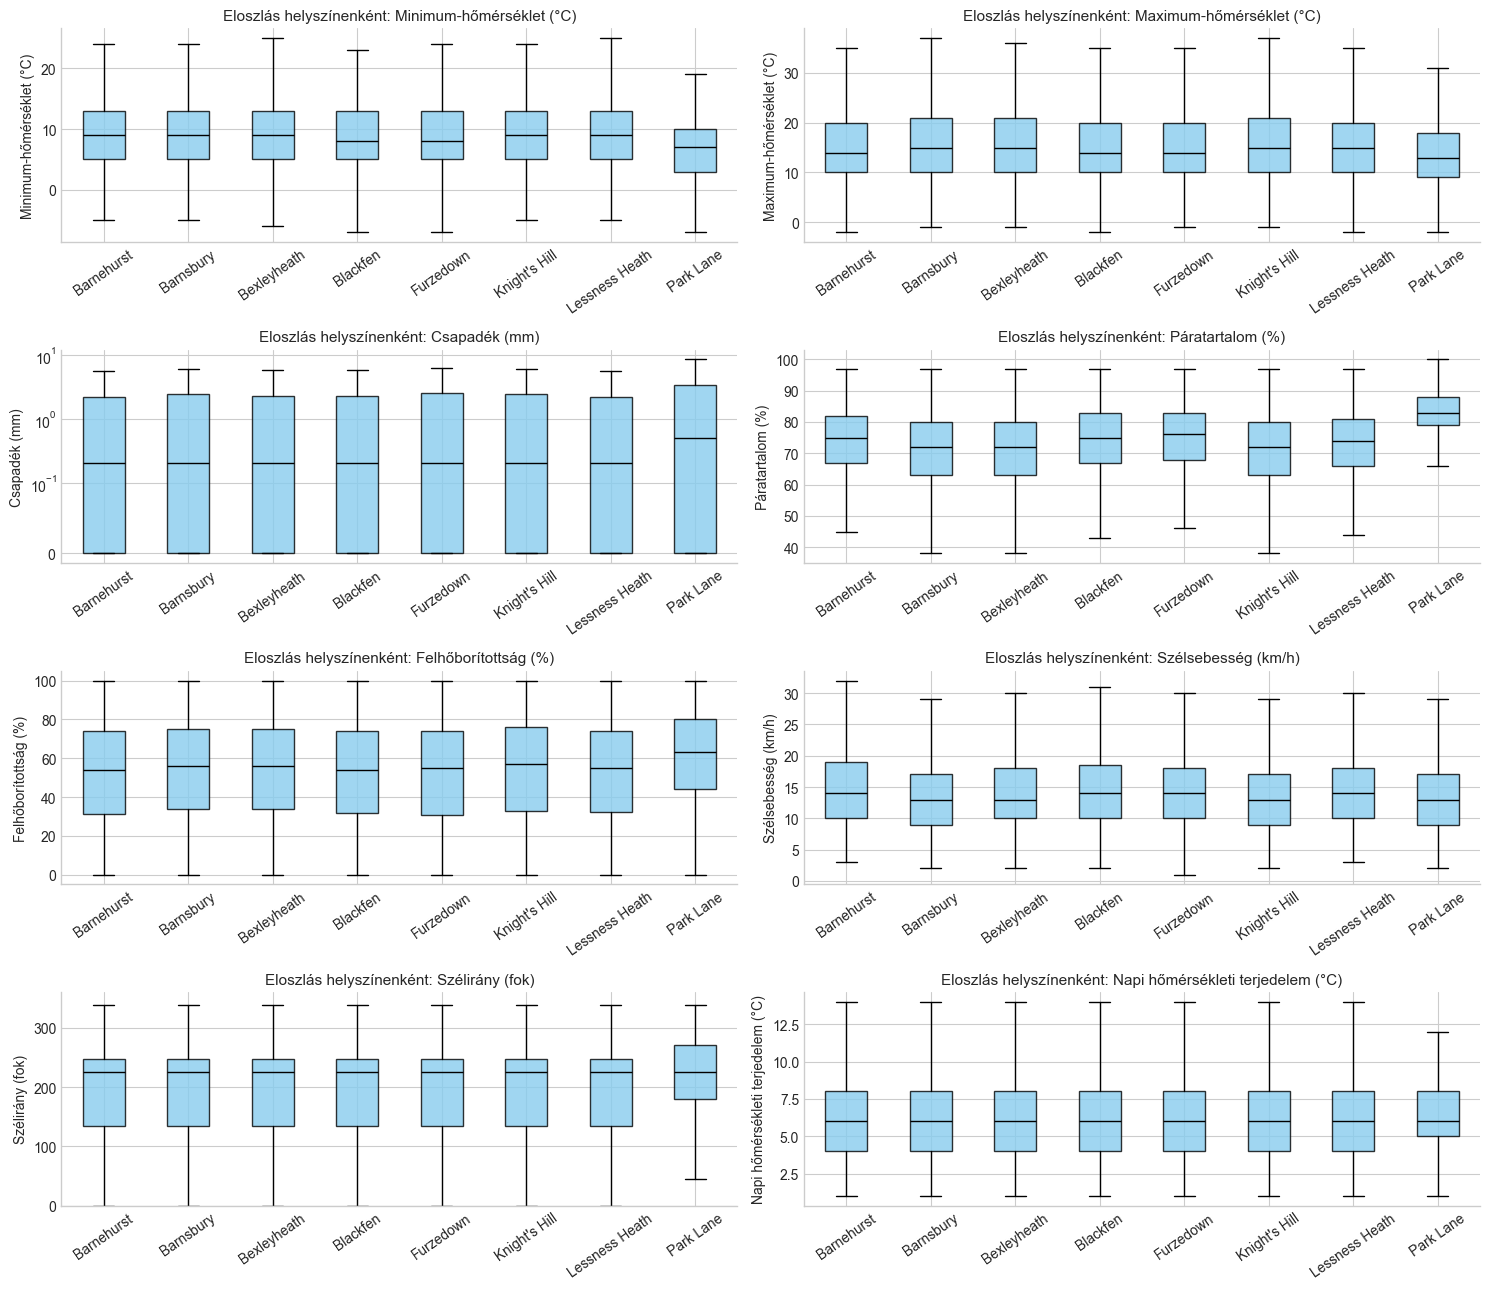

C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=month_labels, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=month_labels, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=month_labels, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\27

C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=month_labels, showfliers=False, patch_artist=True,
C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\2780990420.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=month_labels, showfliers=False, patch_artist=True,


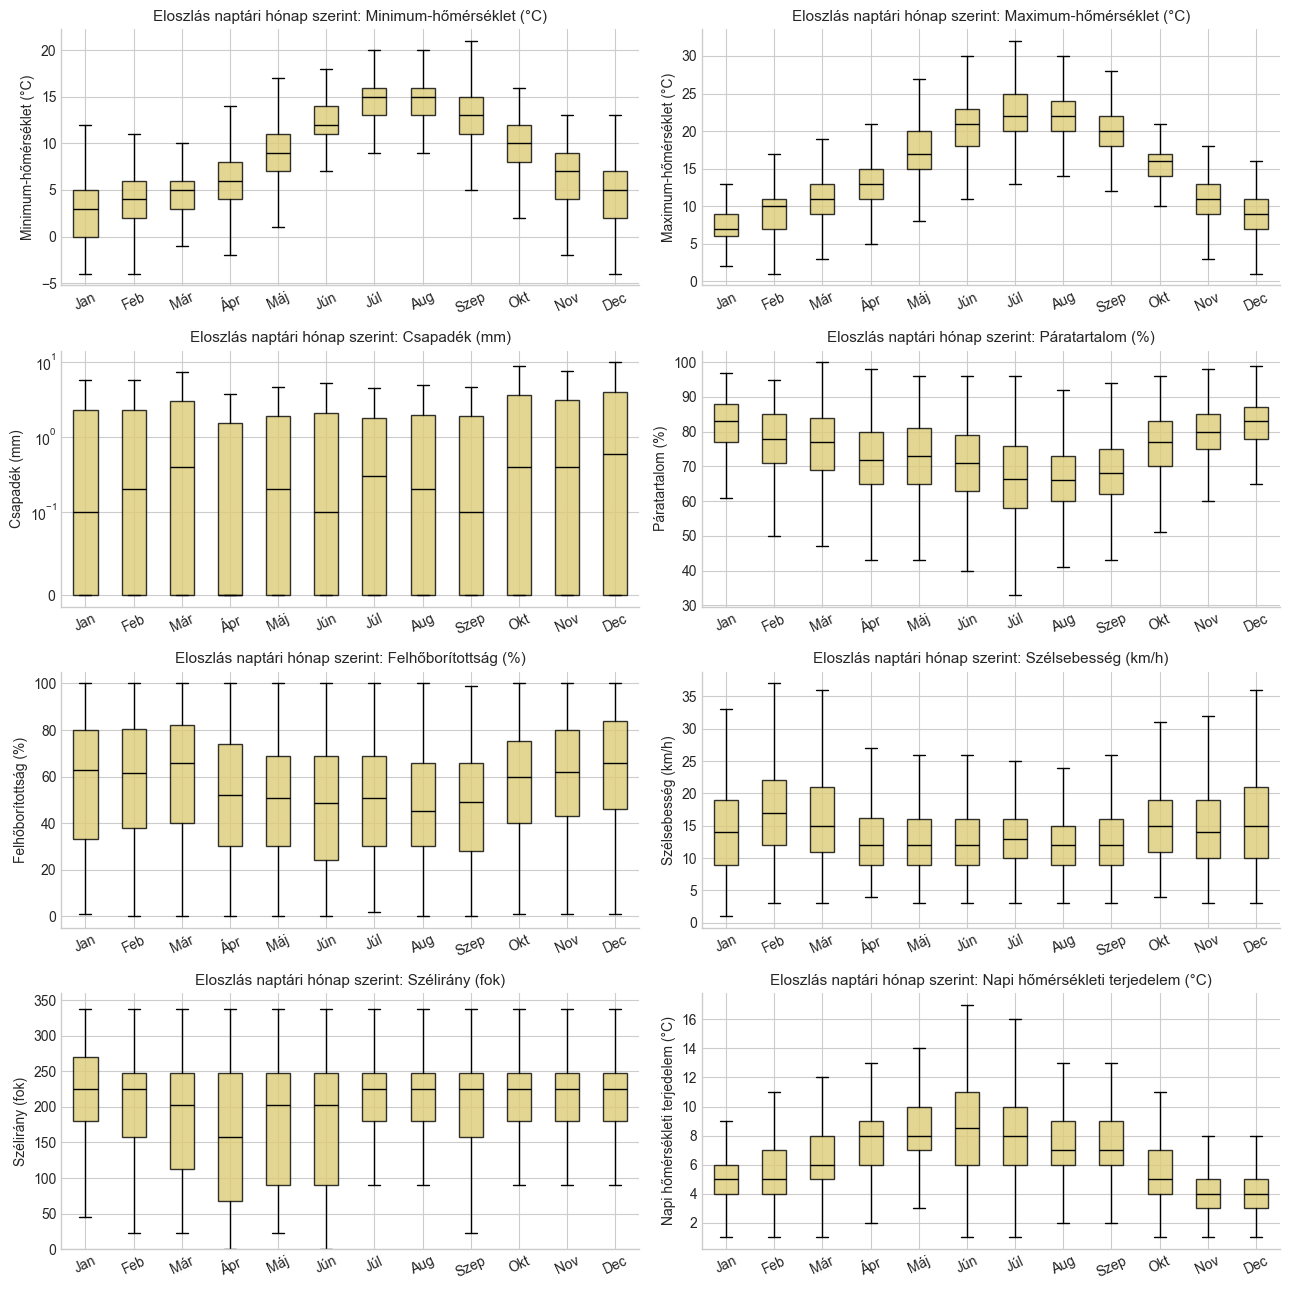

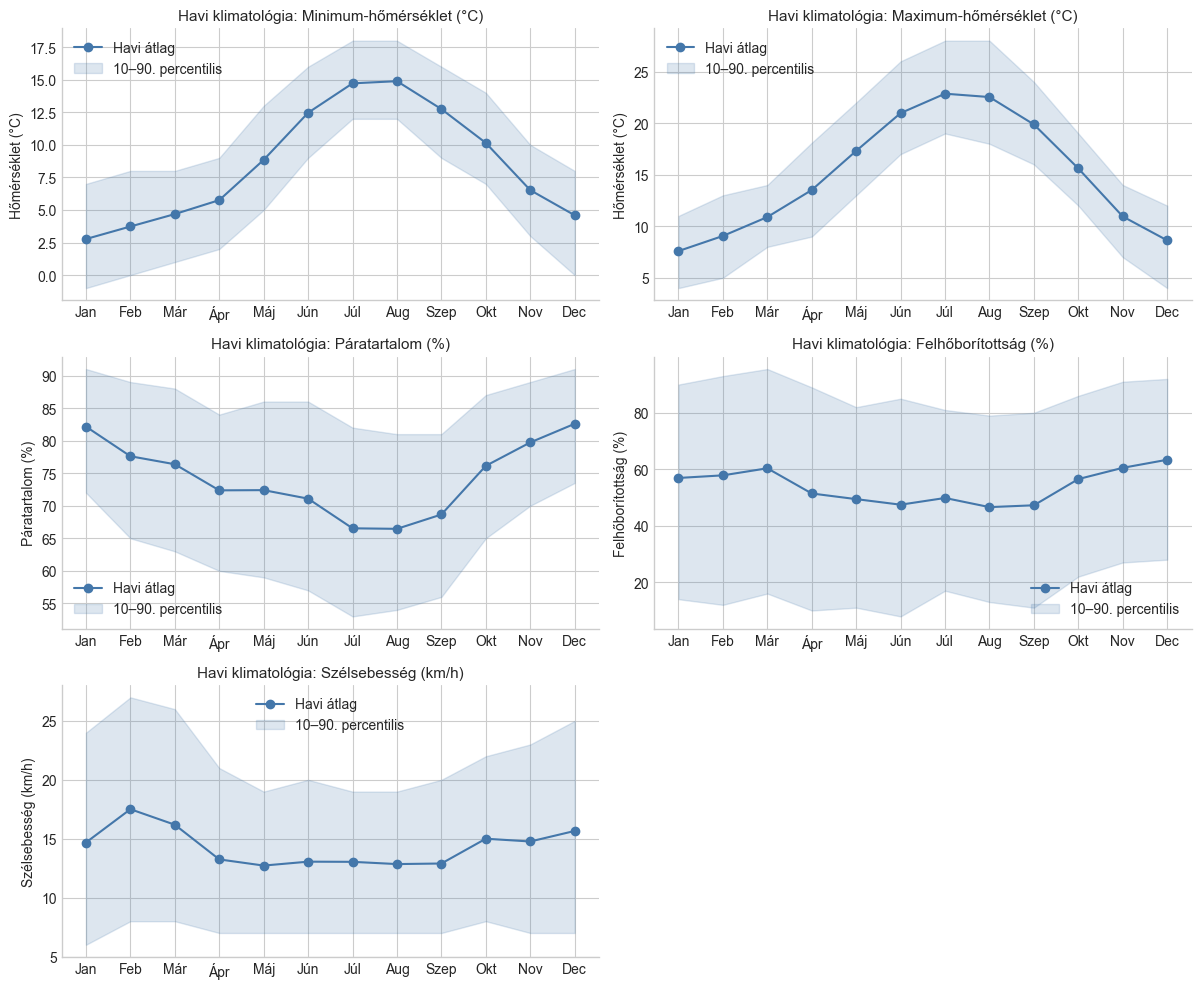

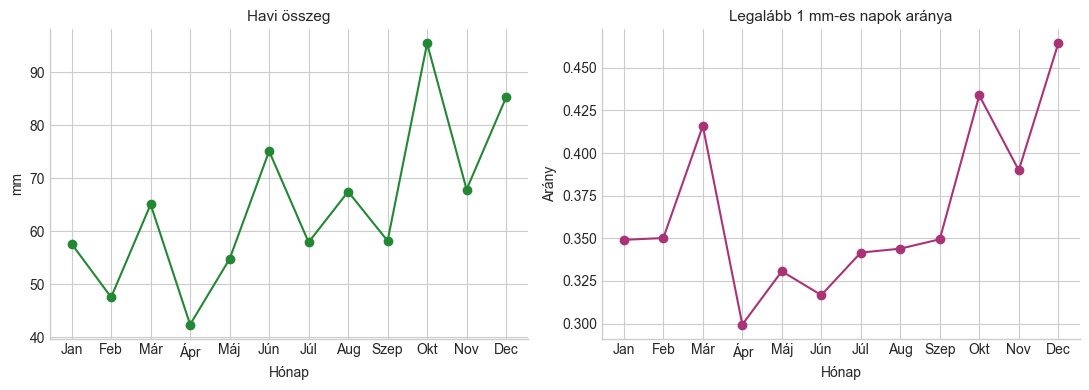

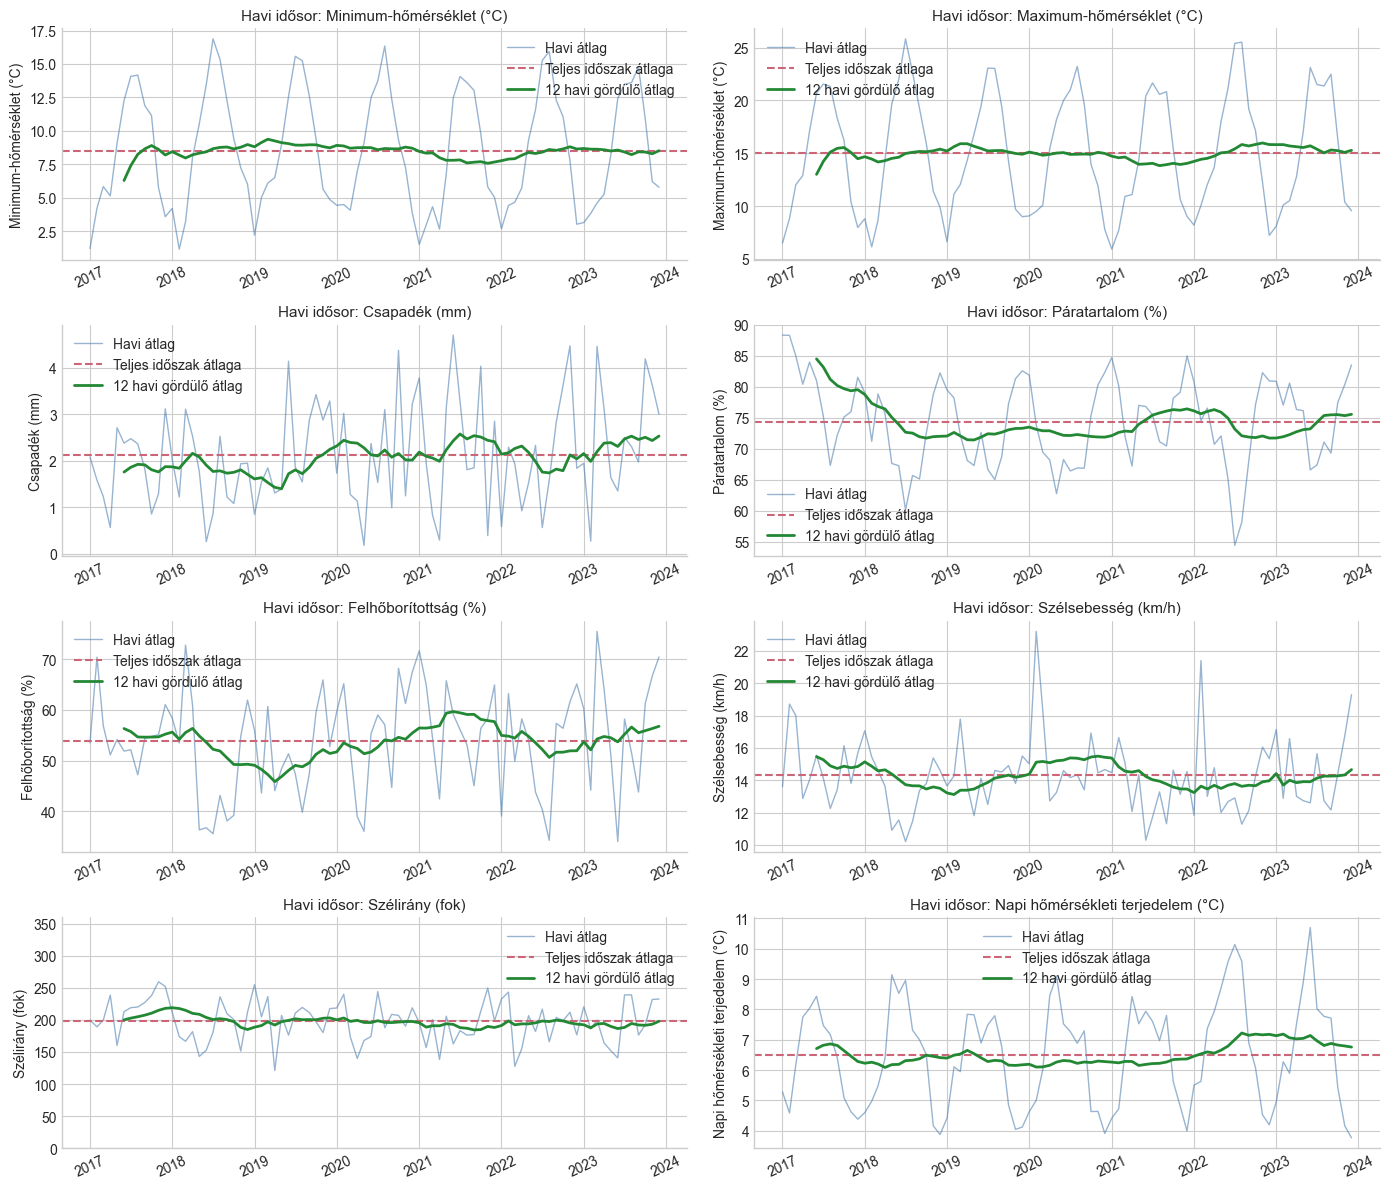

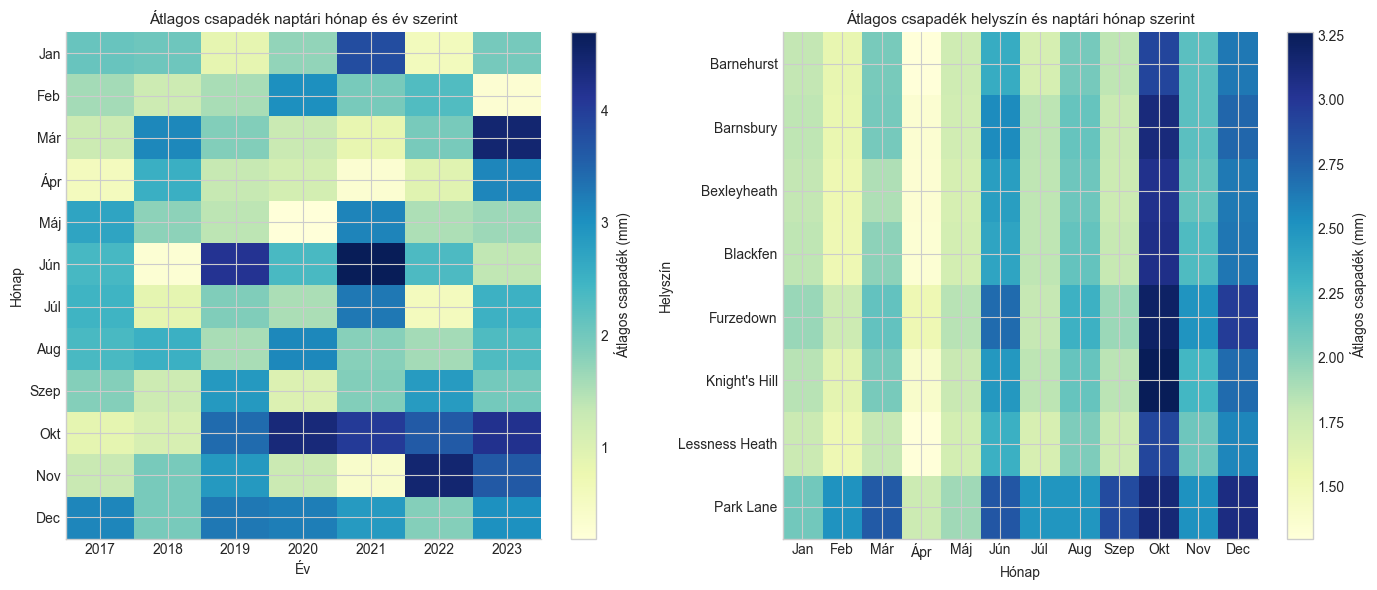

C:\Users\eszti\AppData\Local\Temp\ipykernel_23476\1227782416.py:195: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


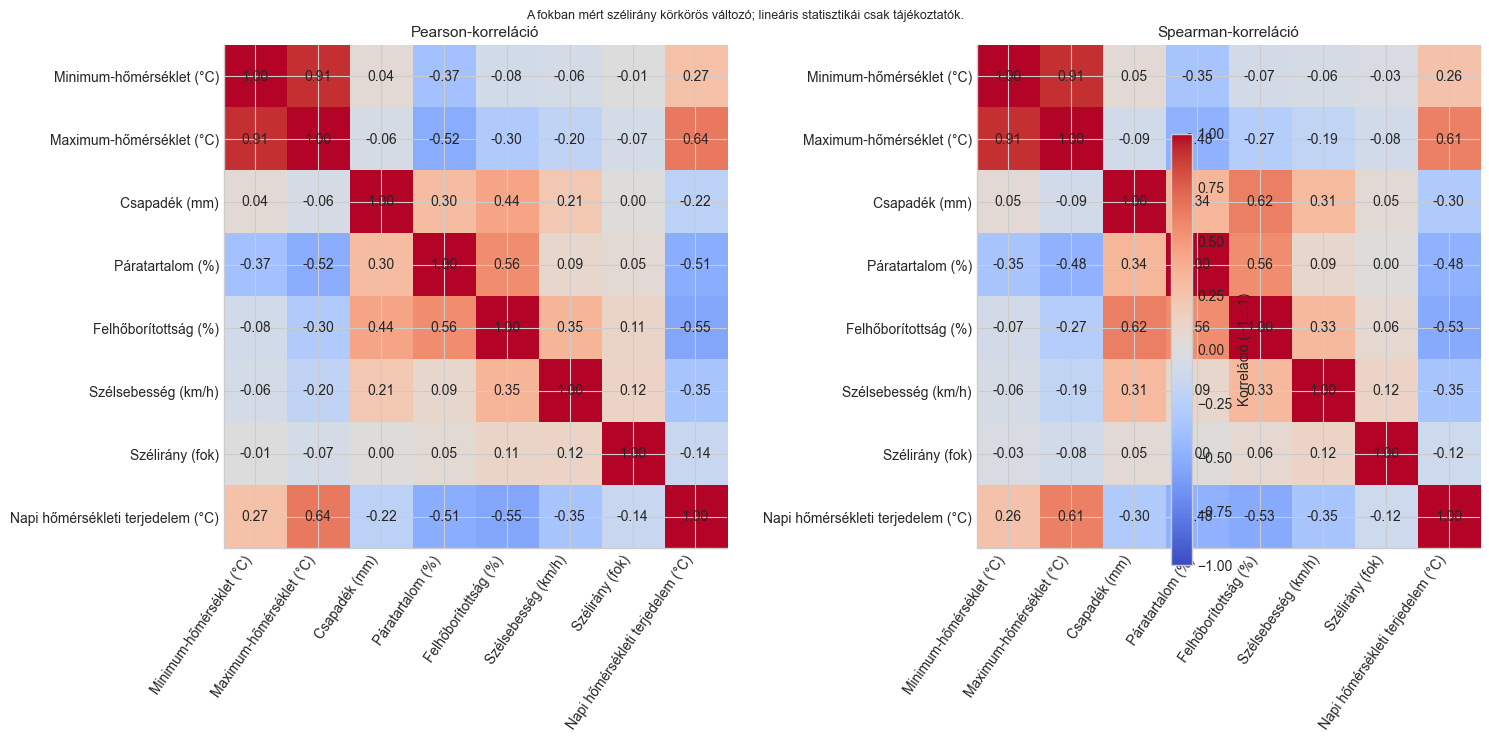

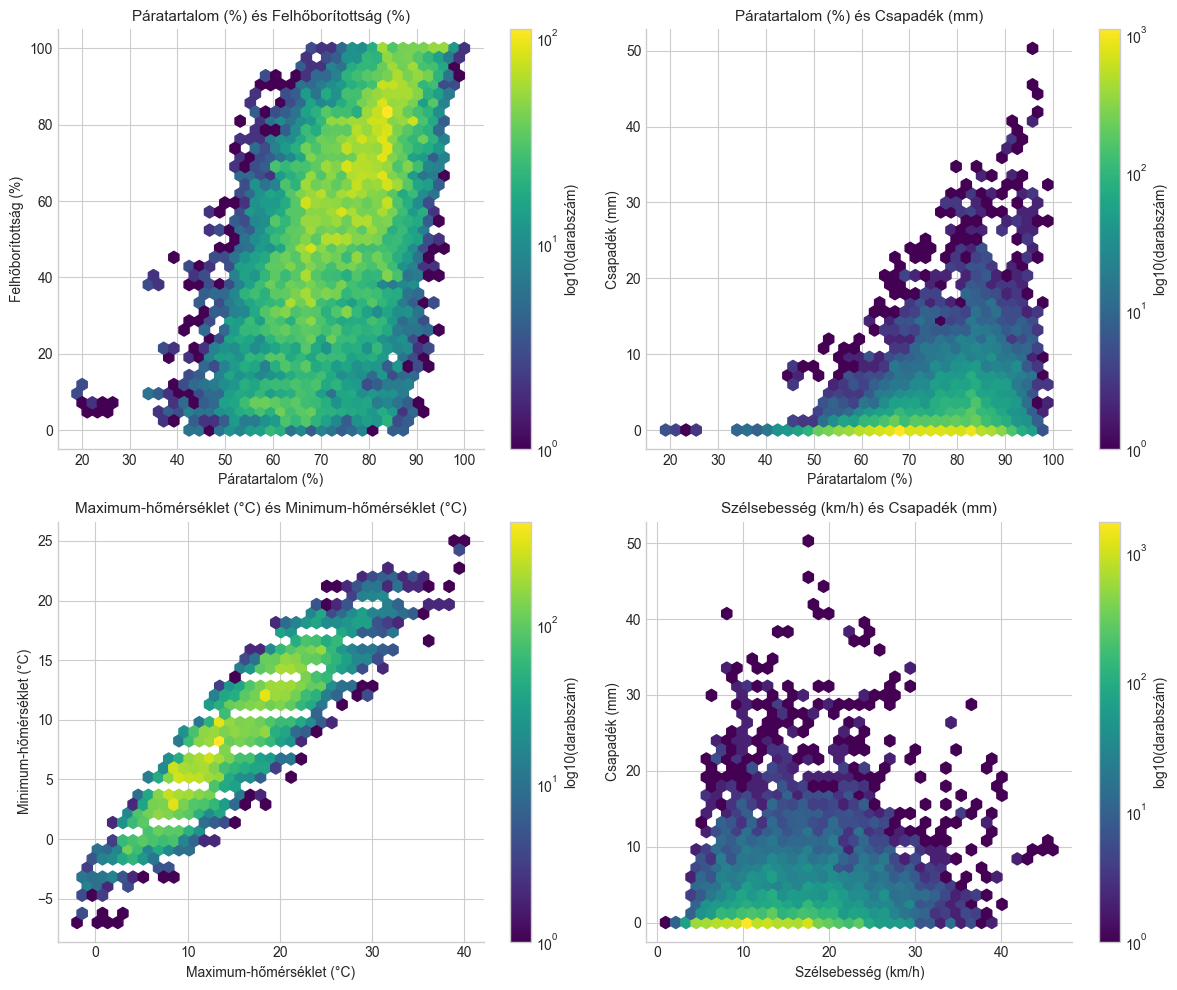

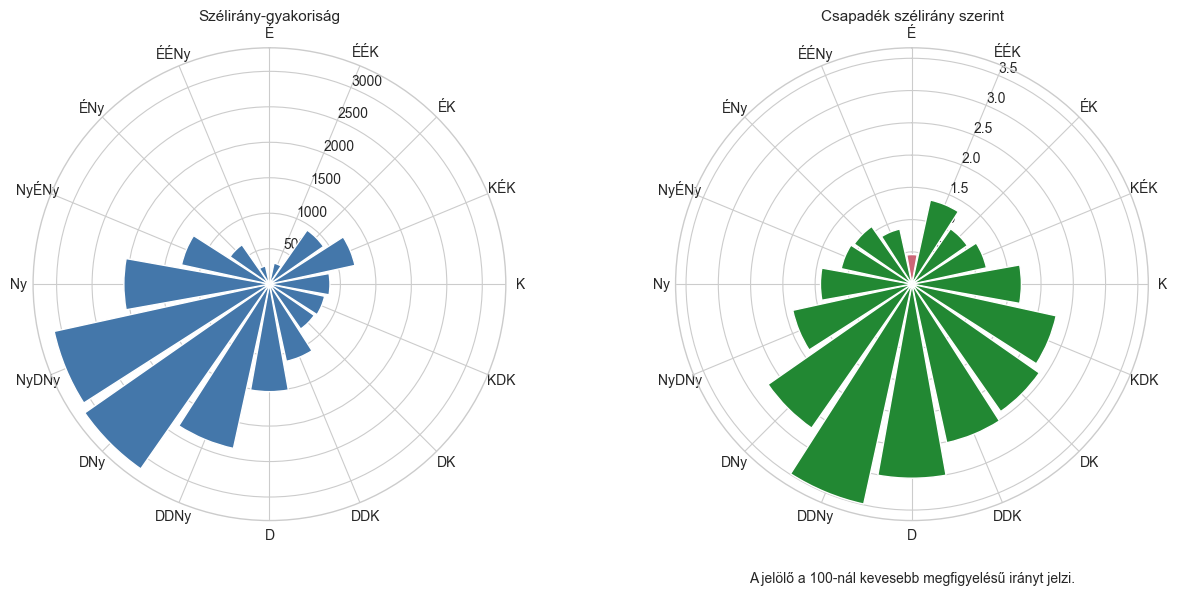

,location,successes,n,share,ci_low,ci_high
0,Barnehurst,912,2555,0.35695,0.33860,0.37573
1,Barnsbury,906,2555,0.35460,0.33628,0.37335
2,Bexleyheath,904,2555,0.35382,0.33551,0.37256
3,Blackfen,901,2555,0.35264,0.33435,0.37138
4,Furzedown,935,2555,0.36595,0.34749,0.38482
5,Knight's Hill,912,2555,0.35695,0.33860,0.37573
6,Lessness Heath,915,2555,0.35812,0.33976,0.37691
7,Park Lane,1092,2555,0.42740,0.40834,0.44667


,year,successes,n,share,ci_low,ci_high
0,2017,1054,2920,0.36096,0.34373,0.37855
1,2018,929,2920,0.31815,0.30151,0.33527
2,2019,1112,2920,0.38082,0.36338,0.39858
3,2020,1012,2920,0.34658,0.32953,0.36403
4,2021,1103,2920,0.37774,0.36033,0.39547
5,2022,1094,2920,0.37466,0.35728,0.39237
6,2023,1173,2920,0.40171,0.38407,0.41961


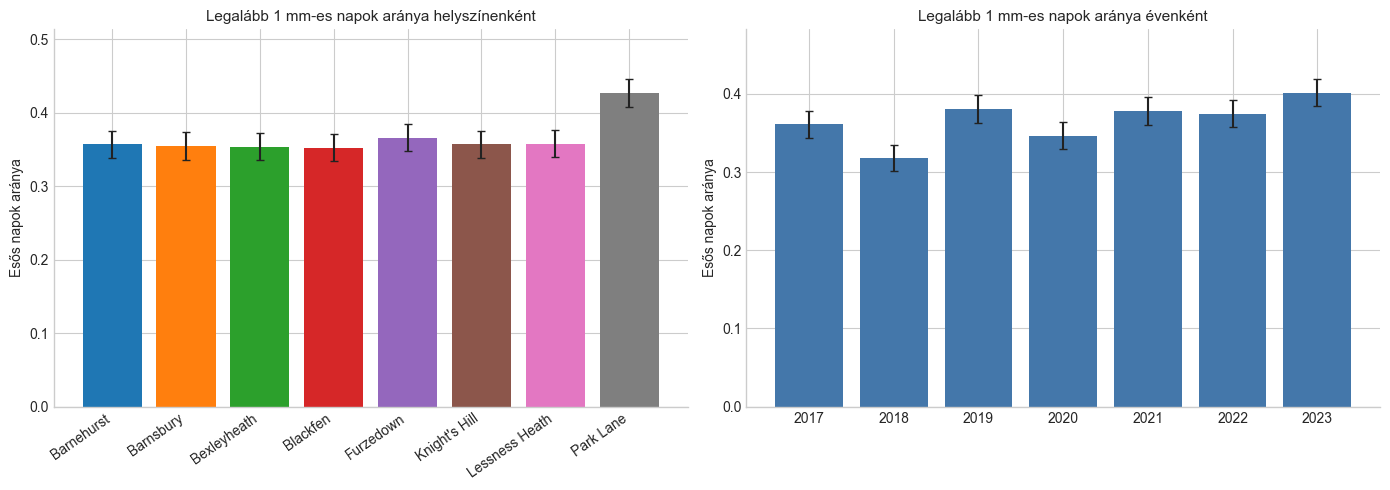

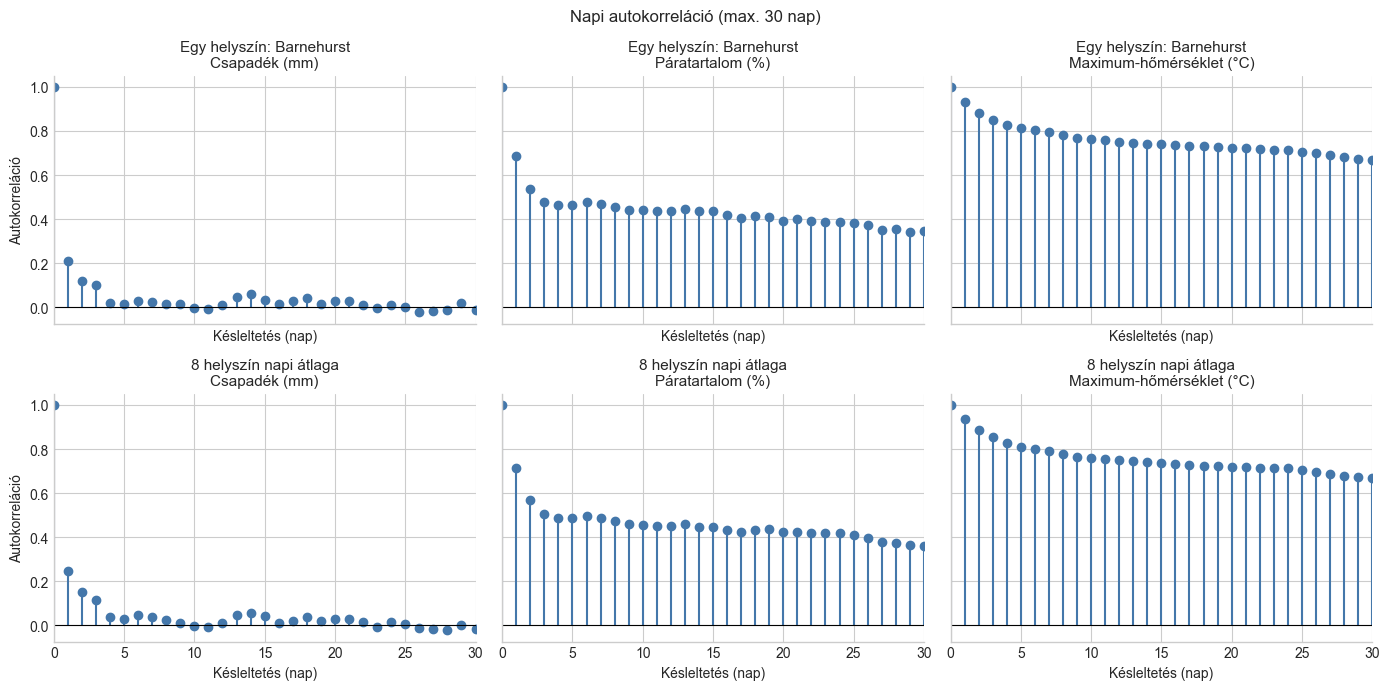

Across **20,440 daily rows**, the histogram and boxplot panels show the distributions of all 8 numeric variables, while the monthly climatology and time-series panels show seasonal patterns and year-to-year movement. The location-level share of days with at least 1 mm rain ranges from **35.3% to 42.7%**; its Wilson intervals are plotted. The autocorrelation panels use calendar-aligned pairs and leave the missing leap day unfilled.

In [4]:
# Histograms with density curves for every numeric variable.
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for ax, variable in zip(axes.flat, NUMERIC_VARS):
    values = df[variable].dropna().to_numpy(dtype=float)
    if variable == "rain":
        values = values[values > 0]
    ax.hist(values, bins=35, density=True, alpha=.55, color="#4477AA", edgecolor="white")
    if variable == "wind_direction_numerical":
        extended = np.concatenate([values - 360, values, values + 360])
        kde = gaussian_kde(extended)
        grid = np.linspace(0, 360, 500)
        ax.plot(grid, kde(grid), color="#CC6677", lw=2)
        ax.set_xlim(0, 360)
    elif np.unique(values).size > 1:
        kde = gaussian_kde(values)
        grid = np.linspace(values.min(), values.max(), 400)
        ax.plot(grid, kde(grid), color="#CC6677", lw=2)
    ax.set_title(T["hist_title"].format(name=NUMERIC_LABELS[variable]))
    ax.set_xlabel(NUMERIC_LABELS[variable])
    ax.set_ylabel(T["density"])
    if variable == "rain":
        ax.set_xscale("symlog", linthresh=.1)
        ax.set_title(f"{T['hist_title'].format(name=NUMERIC_LABELS[variable])}\n{T['rain_symlog_note']}")
    if variable == "wind_direction_numerical":
        ax.text(.02, .97, T["degree_note"], transform=ax.transAxes, va="top", fontsize=8, wrap=True)
save_show(fig, "01_numeric_histograms_kde.png")

location_colors = {location: PALETTE[i % len(PALETTE)] for i, location in enumerate(location_order)}
fig, axes = plt.subplots(4, 2, figsize=(15, 13))
for ax, variable in zip(axes.flat, NUMERIC_VARS):
    groups = [df.loc[df.location.eq(loc), variable].dropna().to_numpy() for loc in location_order]
    ax.boxplot(groups, labels=location_order, showfliers=False, patch_artist=True,
               medianprops={"color": "black"},
               boxprops={"facecolor": "#88CCEE", "alpha": .8})
    ax.set_title(T["box_location"].format(name=NUMERIC_LABELS[variable]))
    ax.set_ylabel(NUMERIC_LABELS[variable])
    ax.tick_params(axis="x", labelrotation=35)
    if variable == "rain":
        ax.set_yscale("symlog", linthresh=.1)
    if variable == "wind_direction_numerical":
        ax.set_ylim(0, 360)
save_show(fig, "02_boxplots_by_location.png")

month_labels = T["month_names"]
fig, axes = plt.subplots(4, 2, figsize=(13, 13))
for ax, variable in zip(axes.flat, NUMERIC_VARS):
    groups = [df.loc[df.month.eq(month), variable].dropna().to_numpy() for month in range(1, 13)]
    ax.boxplot(groups, labels=month_labels, showfliers=False, patch_artist=True,
               medianprops={"color": "black"},
               boxprops={"facecolor": "#DDCC77", "alpha": .8})
    ax.set_title(T["box_month"].format(name=NUMERIC_LABELS[variable]))
    ax.set_ylabel(NUMERIC_LABELS[variable])
    ax.tick_params(axis="x", labelrotation=25)
    if variable == "rain":
        ax.set_yscale("symlog", linthresh=.1)
    if variable == "wind_direction_numerical":
        ax.set_ylim(0, 360)
save_show(fig, "03_boxplots_by_calendar_month.png")

clim_vars = ["min_temp", "max_temp", "humidity", "cloud_cover", "wind_speed"]
clim_axes = {
    "min_temp": "Hőmérséklet (°C)", "max_temp": "Hőmérséklet (°C)",
    "humidity": "Páratartalom (%)", "cloud_cover": "Felhőborítottság (%)",
    "wind_speed": "Szélsebesség (km/h)",
}
if LANG == "en":
    clim_axes = {"min_temp":"Temperature (°C)","max_temp":"Temperature (°C)",
                 "humidity":"Humidity (%)","cloud_cover":"Cloud cover (%)","wind_speed":"Wind speed (km/h)"}
monthly_clim = df.groupby("month")[clim_vars].agg(["mean", lambda x: x.quantile(.1), lambda x: x.quantile(.9)])
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, variable in zip(axes.flat, clim_vars):
    mean = df.groupby("month")[variable].mean()
    low = df.groupby("month")[variable].quantile(.1)
    high = df.groupby("month")[variable].quantile(.9)
    ax.plot(range(1, 13), mean, marker="o", color="#4477AA", label=T["monthly_mean"])
    band_label = "10–90. percentilis" if LANG=="hu" else "10th–90th percentile"
    ax.fill_between(range(1, 13), low, high, color="#4477AA", alpha=.18, label=band_label)
    ax.set_title(T["monthly_clim"].format(name=NUMERIC_LABELS[variable]))
    ax.set_xticks(range(1, 13), month_labels)
    ax.set_ylabel(clim_axes[variable])
    ax.legend(frameon=False)
axes.flat[-1].axis("off")
save_show(fig, "04_monthly_climatology_weather.png")
monthly_rain_by_location_year = (
    df.assign(month_total=df["rain"])
      .groupby(["location", "year", "month"], observed=True)["month_total"].sum()
      .groupby("month").mean()
)
monthly_wet = df.assign(wet=df["rain"].ge(RAIN_THRESHOLD_MM)).groupby("month")["wet"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, 13), monthly_rain_by_location_year.reindex(range(1, 13)), marker="o", color="#228833")
axes[0].set(title=T["monthly_total"], xlabel=T["month"], ylabel="mm")
axes[1].plot(range(1, 13), monthly_wet.reindex(range(1, 13)), marker="o", color="#AA3377")
axes[1].set(title=T["monthly_wet_share"], xlabel=T["month"], ylabel=T["share_axis"])
for ax in axes:
    ax.set_xticks(range(1, 13), month_labels)
save_show(fig, "05_monthly_climatology_rain.png")

monthly_ts = df.groupby("month_start")[NUMERIC_VARS].mean().sort_index()
fig, axes = plt.subplots(4, 2, figsize=(14, 12))
for ax, variable in zip(axes.flat, NUMERIC_VARS):
    series = monthly_ts[variable]
    ax.plot(series.index, series, color="#4477AA", alpha=.55, lw=1, label=T["monthly_mean"])
    ax.axhline(series.mean(), color="#CC6677", linestyle="--", lw=1.5, label=T["pooled_mean"])
    ax.plot(series.rolling(12, min_periods=6).mean().index,
            series.rolling(12, min_periods=6).mean(), color="#228833", lw=2,
            label=T["rolling"])
    ax.set_title(T["series_title"].format(name=NUMERIC_LABELS[variable]))
    ax.set_ylabel(NUMERIC_LABELS[variable])
    if variable == "wind_direction_numerical":
        ax.set_ylim(0, 360)
    ax.tick_params(axis="x", rotation=25)
    ax.legend(frameon=False, ncol=1)
save_show(fig, "06_monthly_time_series.png")

rain_month_year = df.pivot_table(index="month", columns="year", values="rain", aggfunc="mean").reindex(range(1, 13))
rain_location_month = df.pivot_table(index="location", columns="month", values="rain", aggfunc="mean").reindex(index=location_order, columns=range(1, 13))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(rain_month_year, aspect="auto", cmap="YlGnBu")
axes[0].set(title=T["rain_heatmap"], xlabel=T["year"], ylabel=T["month"])
axes[0].set_xticks(range(len(rain_month_year.columns)), rain_month_year.columns)
axes[0].set_yticks(range(12), month_labels)
fig.colorbar(im0, ax=axes[0], label="Átlagos csapadék (mm)" if LANG=="hu" else "Mean rain (mm)")
im1 = axes[1].imshow(rain_location_month, aspect="auto", cmap="YlGnBu")
axes[1].set(title=T["location_heatmap"], xlabel=T["month"], ylabel=T["location"])
axes[1].set_xticks(range(12), month_labels)
axes[1].set_yticks(range(len(location_order)), location_order)
fig.colorbar(im1, ax=axes[1], label="Átlagos csapadék (mm)" if LANG=="hu" else "Mean rain (mm)")
save_show(fig, "07_rain_heatmaps.png")

corr_pearson = df[NUMERIC_VARS].corr(method="pearson")
corr_spearman = df[NUMERIC_VARS].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, matrix, title in zip(axes, [corr_pearson, corr_spearman], [T["corr_pearson"], T["corr_spearman"]]):
    im = ax.imshow(matrix, cmap="coolwarm", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1))
    labels = [NUMERIC_LABELS[v] for v in NUMERIC_VARS]
    ax.set_xticks(range(len(labels)), labels, rotation=55, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_title(title)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{matrix.iloc[i,j]:.2f}", ha="center", va="center", fontsize=10)
fig.colorbar(im, ax=axes, shrink=.8, label="Korreláció (−1…1)" if LANG=="hu" else "Correlation (−1…1)")
fig.suptitle(T["degree_note"], fontsize=9)
save_show(fig, "08_correlation_heatmaps.png")

scatter_pairs = [
    ("humidity", "cloud_cover"), ("humidity", "rain"),
    ("max_temp", "min_temp"), ("wind_speed", "rain"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (x, y) in zip(axes.flat, scatter_pairs):
    hb = ax.hexbin(df[x], df[y], gridsize=38, mincnt=1, bins="log", cmap="viridis")
    ax.set(title=T["scatter_title"].format(x=NUMERIC_LABELS[x], y=NUMERIC_LABELS[y]),
           xlabel=NUMERIC_LABELS[x], ylabel=NUMERIC_LABELS[y])
    fig.colorbar(hb, ax=ax, label="log10(darabszám)" if LANG=="hu" else "log10(count)")
save_show(fig, "09_weather_relationships_hexbin.png")

direction_summary = df.groupby("wind_direction", observed=True).agg(
    count=("rain", "size"), mean_rain=("rain", "mean")
).reindex(COMPASS).fillna(0)
direction_summary.to_csv(TABLES_DIR / "wind_direction_rain_summary.csv", encoding="utf-8-sig")
theta = np.arange(16) * 2 * np.pi / 16
width = 2 * np.pi / 16
fig, axes = plt.subplots(1, 2, figsize=(13, 6), subplot_kw={"projection": "polar"})
axes[0].bar(theta, direction_summary["count"], width=width*.9, color="#4477AA", edgecolor="white")
axes[0].set_theta_zero_location("N")
axes[0].set_theta_direction(-1)
axes[0].set_xticks(theta, [T[c] if c in T else c for c in COMPASS])
axes[0].set_title(T["direction_freq"], pad=20)
low_count = direction_summary["count"].lt(100).to_numpy()
colors = ["#CC6677" if low else "#228833" for low in low_count]
axes[1].bar(theta, direction_summary["mean_rain"], width=width*.9, color=colors, edgecolor="white")
axes[1].set_theta_zero_location("N")
axes[1].set_theta_direction(-1)
axes[1].set_xticks(theta, [T[c] if c in T else c for c in COMPASS])
axes[1].set_title(T["direction_rain"], pad=20)
axes[1].text(.5, -.13, T["rain_direction_note"], transform=axes[1].transAxes, ha="center", fontsize=10)
save_show(fig, "10_wind_roses.png")

def wilson_interval(successes, n, z=1.959963984540054):
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return center-half, center+half

def rainy_ci_table(group_columns):
    rows = []
    grouped = df.groupby(group_columns, observed=True, sort=True)
    for key, group in grouped:
        key = key if isinstance(key, tuple) else (key,)
        n = len(group)
        successes = int(group["rain"].ge(RAIN_THRESHOLD_MM).sum())
        low, high = wilson_interval(successes, n)
        rows.append({**dict(zip(group_columns, key)), "successes": successes,
                     "n": n, "share": successes/n, "ci_low": low, "ci_high": high})
    return pd.DataFrame(rows)

ci_location = rainy_ci_table(["location"])
ci_year = rainy_ci_table(["year"])
save_table(ci_location.round(5), "rainy_share_ci_by_location.csv")
save_table(ci_year.round(5), "rainy_share_ci_by_year.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, x, title in [
    (axes[0], ci_location, "location", T["ci_title_location"]),
    (axes[1], ci_year, "year", T["ci_title_year"]),
]:
    xpos = np.arange(len(table))
    ax.bar(xpos, table["share"], color=[location_colors.get(str(v), "#4477AA") for v in table[x]] if x=="location" else "#4477AA")
    ax.errorbar(xpos, table["share"],
                yerr=[table["share"]-table["ci_low"], table["ci_high"]-table["share"]],
                fmt="none", ecolor="#222222", capsize=3)
    ax.set_xticks(xpos, table[x].astype(str), rotation=35 if x=="location" else 0, ha="right" if x=="location" else "center")
    ax.set_ylim(0, min(1, max(.1, table["ci_high"].max()*1.15)))
    ax.set(title=title, ylabel=T["rain_share"])
save_show(fig, "11_rainy_share_wilson_ci.png")

def pairwise_acf(series, dates, max_lag=30):
    values = pd.Series(np.asarray(series, dtype=float), index=pd.DatetimeIndex(dates))
    full_dates = pd.date_range(values.index.min(), values.index.max(), freq="D")
    values = values.reindex(full_dates).to_numpy()
    result = [1.0]
    for lag in range(1, max_lag + 1):
        left, right = values[:-lag], values[lag:]
        valid = np.isfinite(left) & np.isfinite(right)
        result.append(float(np.corrcoef(left[valid], right[valid])[0, 1]) if valid.sum() > 2 else np.nan)
    return np.asarray(result)

acf_variables = ["rain", "humidity", "max_temp"]
single_location = location_order[0]
site_data = df.loc[df.location.eq(single_location)].sort_values("date")
daily_average = df.groupby("date", as_index=False)[acf_variables].mean()
lags = np.arange(31)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
for col, variable in enumerate(acf_variables):
    for row, (series_df, title) in enumerate([
        (site_data, f"{T['single_site']}: {single_location}"),
        (daily_average, T["site_average"]),
    ]):
        acf = pairwise_acf(series_df[variable], series_df["date"])
        axes[row, col].stem(lags, acf, linefmt="#4477AA", markerfmt="o", basefmt=" ")
        axes[row, col].axhline(0, color="black", lw=.8)
        axes[row, col].set_title(f"{title}\n{NUMERIC_LABELS[variable]}")
        axes[row, col].set_xlabel(T["lag"])
        if col == 0:
            axes[row, col].set_ylabel(T["acf"])
        axes[row, col].set_xlim(0, 30)
fig.suptitle(T["acfs_title"])
save_show(fig, "12_daily_autocorrelation.png")

rainy_share_min = float(ci_location["share"].min())
rainy_share_max = float(ci_location["share"].max())
display(Markdown(
    f"Across **{len(df):,} daily rows**, the histogram and boxplot panels show the distributions of all "
    f"{len(NUMERIC_VARS)} numeric variables, while the monthly climatology and time-series panels show seasonal "
    f"patterns and year-to-year movement. The location-level share of days with at least 1 mm rain ranges from "
    f"**{pct(rainy_share_min)} to {pct(rainy_share_max)}**; its Wilson intervals are plotted. "
    f"The autocorrelation panels use calendar-aligned pairs and leave the missing leap day unfilled."
))

## 4. Egyszerű statisztikai összehasonlítások

In [5]:
def epsilon_squared(h_stat, n, k):
    return max(0.0, float((h_stat - k + 1) / (n - k))) if n > k else np.nan

def kruskal_by(data, variable, group_column):
    arrays = [g[variable].dropna().to_numpy() for _, g in data.groupby(group_column, observed=True)]
    arrays = [values for values in arrays if len(values) > 0]
    h_stat, p_value = kruskal(*arrays)
    n = sum(len(values) for values in arrays)
    return {
        "variable": variable, "grouping": group_column, "groups": len(arrays),
        "n": n, "H": float(h_stat), "p_value": float(p_value),
        "epsilon_squared": epsilon_squared(h_stat, n, len(arrays)),
    }

kruskal_rows = []
for variable in NUMERIC_VARS:
    kruskal_rows.append(kruskal_by(df, variable, "location"))
    kruskal_rows.append(kruskal_by(df, variable, "month"))
kruskal_results = pd.DataFrame(kruskal_rows)
print("Kruskal–Wallis-próbák helyszínek és összevont naptári hónapok szerint:")
save_table(kruskal_results, "kruskal_wallis_effect_sizes.csv")

df["rainy_today"] = df["rain"].ge(RAIN_THRESHOLD_MM)
rain_by_location = pd.crosstab(df["location"], df["rainy_today"])
chi2, chi_p, dof, expected = chi2_contingency(rain_by_location)
n = rain_by_location.to_numpy().sum()
cramers_v = float(np.sqrt(chi2 / (n * min(rain_by_location.shape[0]-1, rain_by_location.shape[1]-1))))
rain_chi_square = pd.DataFrame([{
    "threshold_mm": RAIN_THRESHOLD_MM, "chi2": float(chi2), "df": int(dof),
    "p_value": float(chi_p), "cramers_v": cramers_v, "n": int(n),
}])
print("A csapad\u00e9kos napok ar\u00e1ny\u00e1nak khi-n\u00e9gyzet-pr\u00f3b\u00e1ja helysz\u00ednenk\u00e9nt:")
save_table(rain_chi_square, "rainy_share_chi_square_cramers_v.csv")
display(Markdown(
    f"A helyszínek és hónapok közül a legnagyobb Kruskal–Wallis-hatásméret becslése "
    f"\u03b5\xb2={kruskal_results['epsilon_squared'].max():.4f}; a legkisebb p-\u00e9rt\u00e9k "
    f"{kruskal_results['p_value'].min():.3g}. A csapadékos napok arányának összehasonlítása: "
    f"\u03c7\xb2({int(dof)})={chi2:.1f}, p={chi_p:.3g}, Cram\u00e9r-f\u00e9le V={cramers_v:.3f}. "
    "**Ezek a p-\u00e9rt\u00e9kek csak t\u00e1j\u00e9koztat\u00f3 jelleg\u0171ek:** a napi id\u0151j\u00e1r\u00e1si megfigyel\u00e9sek autokorrel\u00e1ltak, ez\u00e9rt a szok\u00e1sos "
    "f\u00fcggetlen megfigyel\u00e9seket felt\u00e9telez\u0151 referenciaeloszl\u00e1sok nem alkalmazhat\u00f3k teljes m\u00e9rt\u00e9kben."
))


Kruskal–Wallis-próbák helyszínek és összevont naptári hónapok szerint:


,variable,grouping,groups,n,H,p_value,epsilon_squared
0,min_temp,location,8,20440,344.850993,1.558804e-70,0.016535
1,min_temp,month,12,20440,14668.981337,0.000000e+00,0.717544
2,max_temp,location,8,20440,193.894790,2.250466e-38,0.009147
3,max_temp,month,12,20440,15533.343979,0.000000e+00,0.759856
4,rain,location,8,20440,73.190807,3.339333e-13,0.003240
5,rain,month,12,20440,189.388148,1.175959e-34,0.008733
6,humidity,location,8,20440,2258.475594,0.000000e+00,0.110194
7,humidity,month,12,20440,4977.690392,0.000000e+00,0.243132
8,cloud_cover,location,8,20440,159.488085,4.110814e-31,0.007463
9,cloud_cover,month,12,20440,985.908600,2.067357e-204,0.047724


A csapadékos napok arányának khi-négyzet-próbája helyszínenként:


,threshold_mm,chi2,df,p_value,cramers_v,n
0,1.0,49.033342,7,2.235083e-08,0.048978,20440


A helyszínek és hónapok közül a legnagyobb Kruskal–Wallis-hatásméret becslése ε²=0.7599; a legkisebb p-érték 0. A csapadékos napok arányának összehasonlítása: χ²(7)=49.0, p=2.24e-08, Cramér-féle V=0.049. **Ezek a p-értékek csak tájékoztató jellegűek:** a napi időjárási megfigyelések autokorreláltak, ezért a szokásos független megfigyeléseket feltételező referenciaeloszlások nem alkalmazhatók teljes mértékben.

## 5. Feltárás a következő napi csapadék alapján

Célváltozó létrehozása és osztálymegoszlás:


,valid_pairs,dropped_without_valid_next_day,tomorrow_rain_1mm_count,tomorrow_rain_1mm_share,tomorrow_dry_share
0,20424,16,7469,0.3657,0.6343


Az aznapi csapadékos arány érzékenysége a küszöbértékre:


,threshold_mm,rainy_today_count,rainy_today_share
0,0.1,11607,0.56830
1,0.5,8979,0.43963
2,1.0,7462,0.36535
3,2.0,5702,0.27918
4,5.0,2951,0.14449
5,10.0,1068,0.05229


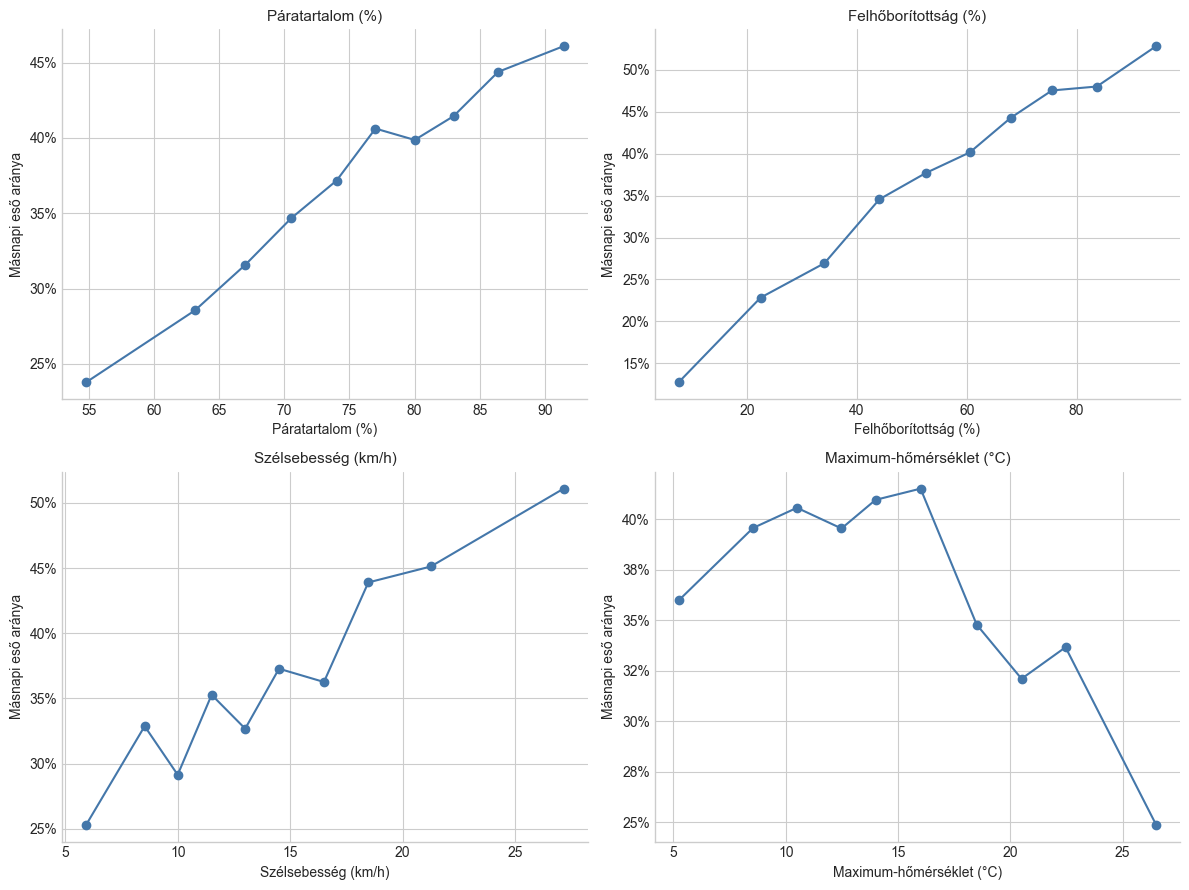

Másnapi csapadékos arány jellemzőnkénti decilisek szerint (ábrák és CSV):


,decile,feature_mean,rain_tomorrow_share,n,variable
0,0,54.79949,0.23781,2359,humidity
1,1,63.15240,0.28558,2185,humidity
2,2,67.00867,0.31579,1615,humidity
3,3,70.53966,0.34677,2307,humidity
4,4,74.01371,0.37171,1824,humidity
5,5,76.99466,0.40622,2058,humidity
6,6,80.00623,0.39866,2087,humidity
7,7,82.98440,0.41443,2051,humidity
8,8,86.40101,0.44383,2172,humidity
9,9,91.43092,0.46093,1766,humidity


Másnapi csapadékos arány a mai szélirány szerint:


,wind_direction,n,rain_tomorrow_share
0,N,17,0.11765
1,NNE,303,0.08581
2,NE,929,0.16792
3,ENE,1234,0.22285
4,E,853,0.27667
5,ESE,796,0.35678
6,SE,770,0.38182
7,SSE,1113,0.44744
8,S,1514,0.47622
9,SSW,2362,0.51524


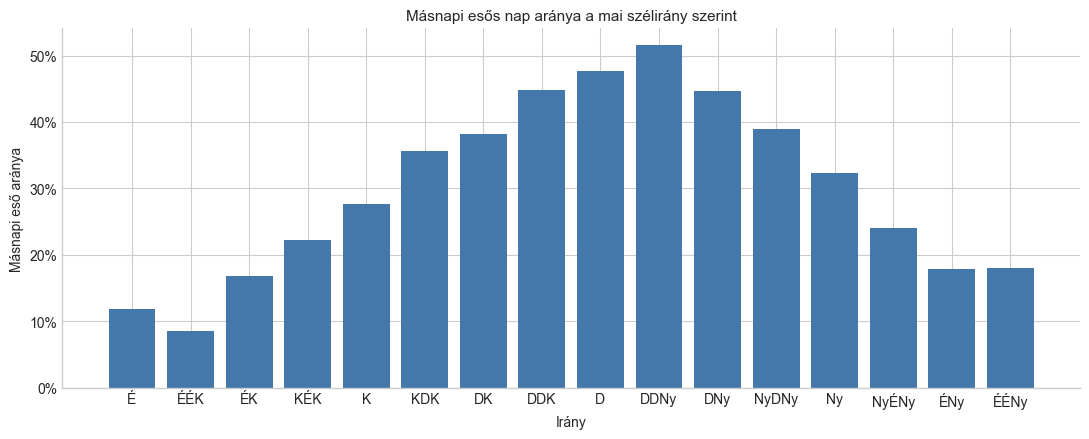

2×2 kereszttáblázat: mai és másnapi csapadék:


rain_tomorrow,0,1
rainy_today_label,,
Esős (>=1 mm),3381,4081
Száraz (<1 mm),9574,3388


2×2 soron belüli arányok:


rain_tomorrow,0,1
rainy_today_label,,
Esős (>=1 mm),0.453096,0.546904
Száraz (<1 mm),0.738621,0.261379


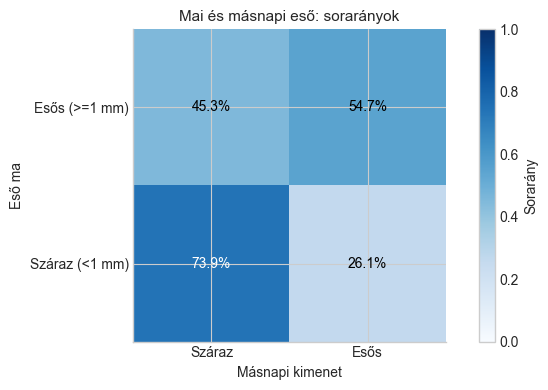

Egyszerű leíró viszonyító szabályok pontossága (nem illesztett modellek):


,descriptive_rule,accuracy
0,always_dry,0.63430
1,tomorrow_equals_today,0.66858


A 20,424 sorból **16** esethez nem tartozik érvényes, következő naptári napi pár, ezeket kizártuk; a 2020-02-28-i sort a hiányzó 2020-02-29 miatt kizártuk. A pozitív osztály (másnap legalább 1 mm csapadék) aránya **36.6%**. A mindig száraz viszonyító szabály pontossága **63.4%**, a mai csapadékstátusz másnapra másolása pedig **66.9%**; ezek leíró viszonyító szabályok, nem prediktív modellek.

A README 15 sorral elkészült: C:\Users\eszti\Bakos-Eszter---data-science-kurzus\projekt\eda_london\README.md.
Elkészült ábrák: 15; CSV-táblázatok: 27.


In [6]:
target_frame = df.sort_values(["location", "date"]).copy()
next_date = target_frame.groupby("location", sort=False)["date"].shift(-1)
next_rain = target_frame.groupby("location", sort=False)["rain"].shift(-1)
valid_next_day = next_date.sub(target_frame["date"]).eq(pd.Timedelta(days=1))
target_frame["rain_tomorrow"] = np.where(valid_next_day, next_rain.ge(RAIN_THRESHOLD_MM).astype(float), np.nan)
target_frame["rainy_today"] = target_frame["rain"].ge(RAIN_THRESHOLD_MM)
target = target_frame.loc[target_frame["rain_tomorrow"].notna()].copy()
dropped_no_next_day = int(target_frame["rain_tomorrow"].isna().sum())
target["rain_tomorrow"] = target["rain_tomorrow"].astype(int)
target["rainy_today_label"] = np.where(target["rainy_today"], "Esős (>=1 mm)", "Száraz (<1 mm)")
target["rainy_today_label"] = target["rainy_today_label"] if LANG=="hu" else np.where(target["rainy_today"], "Rainy (>=1 mm)", "Dry (<1 mm)")

target_balance = pd.DataFrame([{
    "valid_pairs": len(target), "dropped_without_valid_next_day": dropped_no_next_day,
    "tomorrow_rain_1mm_count": int(target["rain_tomorrow"].sum()),
    "tomorrow_rain_1mm_share": float(target["rain_tomorrow"].mean()),
    "tomorrow_dry_share": float(target["rain_tomorrow"].eq(0).mean()),
}])
print("Célváltozó létrehozása és osztálymegoszlás:")
save_table(target_balance.round(5), "rain_tomorrow_class_balance.csv")
assert len(target) + dropped_no_next_day == len(target_frame)
assert not (target["date"].dt.strftime("%m-%d").eq("02-28") & target["date"].dt.year.eq(2020)).any()

sensitivity = pd.DataFrame([
    {"threshold_mm": threshold,
     "rainy_today_count": int(target["rain"].ge(threshold).sum()),
     "rainy_today_share": float(target["rain"].ge(threshold).mean())}
    for threshold in RAIN_THRESHOLDS_MM
])
print("Az aznapi csapadékos arány érzékenysége a küszöbértékre:")
save_table(sensitivity.round(5), "rain_threshold_sensitivity_valid_pairs.csv")

feature_vars = ["humidity", "cloud_cover", "wind_speed", "max_temp"]
feature_deciles = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, variable in zip(axes.flat, feature_vars):
    labels = pd.qcut(target[variable], 10, labels=False, duplicates="drop")
    summary = target.assign(decile=labels).groupby("decile", observed=True).agg(
        feature_mean=(variable, "mean"), rain_tomorrow_share=("rain_tomorrow", "mean"),
        n=("rain_tomorrow", "size"),
    ).reset_index()
    feature_deciles[variable] = summary
    ax.plot(summary["feature_mean"], summary["rain_tomorrow_share"], marker="o", color="#4477AA")
    ax.set(title=NUMERIC_LABELS[variable], xlabel=NUMERIC_LABELS[variable], ylabel=T["target_share"])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
save_show(fig, "13_tomorrow_rain_by_feature_decile.png")
decile_export = pd.concat(
    [table.assign(variable=variable) for variable, table in feature_deciles.items()],
    ignore_index=True,
)
print("Másnapi csapadékos arány jellemzőnkénti decilisek szerint (ábrák és CSV):")
save_table(decile_export.round(5), "rain_tomorrow_by_feature_decile.csv")

direction_tomorrow = target.groupby("wind_direction", observed=True).agg(
    n=("rain_tomorrow", "size"), rain_tomorrow_share=("rain_tomorrow", "mean")
).reindex(COMPASS)
print("M\u00e1snapi csapad\u00e9kos ar\u00e1ny a mai sz\u00e9lir\u00e1ny szerint:")
save_table(direction_tomorrow.reset_index().round(5), "rain_tomorrow_by_wind_direction.csv")
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(np.arange(16), direction_tomorrow["rain_tomorrow_share"], color="#4477AA")
ax.set_xticks(np.arange(16), [T[c] if c in T else c for c in COMPASS])
ax.set(title="Másnapi esős nap aránya a mai szélirány szerint" if LANG=="hu" else "Next-day rainy share by today's wind direction",
       xlabel=T["direction_axis"], ylabel=T["target_share"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
save_show(fig, "14_tomorrow_rain_by_wind_direction.png")

today_table = pd.crosstab(target["rainy_today_label"], target["rain_tomorrow"])
today_row_share = today_table.div(today_table.sum(axis=1), axis=0)
today_counts = today_table.copy()
today_counts.to_csv(TABLES_DIR / "rain_tomorrow_by_rain_today_counts.csv", encoding="utf-8-sig")
today_row_share.to_csv(TABLES_DIR / "rain_tomorrow_by_rain_today_row_percentages.csv", encoding="utf-8-sig")
print("2×2 kereszttáblázat: mai és másnapi csapadék:")
display(today_counts)
print("2\xd72 soron bel\u00fcli ar\u00e1nyok:")
display(today_row_share)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(today_row_share.to_numpy(), vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(today_row_share.shape[1]), ["Száraz" if LANG=="hu" else "Dry", "Esős" if LANG=="hu" else "Rainy"])
ax.set_yticks(range(today_row_share.shape[0]), today_row_share.index)
ax.set(title="Mai és másnapi eső: sorarányok" if LANG=="hu" else "Rain today and tomorrow: row percentages",
       xlabel=T["outcome"], ylabel=T["today_rain"])
for i in range(today_row_share.shape[0]):
    for j in range(today_row_share.shape[1]):
        ax.text(j, i, f"{today_row_share.iloc[i,j]:.1%}", ha="center", va="center",
                color="white" if today_row_share.iloc[i,j] > .55 else "black")
fig.colorbar(im, ax=ax, label=T["share"])
save_show(fig, "15_rain_today_tomorrow_table.png")

always_dry_accuracy = float(target["rain_tomorrow"].eq(0).mean())
today_as_tomorrow_accuracy = float(target["rain_tomorrow"].eq(target["rainy_today"].astype(int)).mean())
baseline_table = pd.DataFrame([
    {"descriptive_rule": "always_dry", "accuracy": always_dry_accuracy},
    {"descriptive_rule": "tomorrow_equals_today", "accuracy": today_as_tomorrow_accuracy},
])
print("Egyszer\u0171 le\u00edr\u00f3 viszony\u00edt\u00f3 szab\u00e1lyok pontoss\u00e1ga (nem illesztett modellek):")
save_table(baseline_table.round(5), "naive_reference_accuracies.csv")
display(Markdown(
    f"A {len(target):,} sorból **{dropped_no_next_day:,}** esethez nem tartozik érvényes, következő naptári napi pár, ezeket kizártuk; "
    f"a 2020-02-28-i sort a hi\u00e1nyz\u00f3 2020-02-29 miatt kiz\u00e1rtuk. A pozit\u00edv oszt\u00e1ly (m\u00e1snap legal\u00e1bb 1 mm csapad\u00e9k) "
    f"ar\u00e1nya **{pct(target['rain_tomorrow'].mean())}**. A mindig sz\u00e1raz viszony\u00edt\u00f3 szab\u00e1ly pontoss\u00e1ga "
    f"**{pct(always_dry_accuracy)}**, a mai csapad\u00e9kst\u00e1tusz m\u00e1snapra m\u00e1sol\u00e1sa pedig **{pct(today_as_tomorrow_accuracy)}**; "
    "ezek le\u00edr\u00f3 viszony\u00edt\u00f3 szab\u00e1lyok, nem predikt\u00edv modellek."
))

# README kimenet let\u00e9trehoz\u00e1sa a notebookban kisz\u00e1molt adatokkal.
top_rain_month = int(df.groupby("month")["rain"].mean().idxmax())
warmest_month = int(df.groupby("month")["max_temp"].mean().idxmax())
month_names_hu = ["janu?r", "febru?r", "m?rcius", "?prilis", "m?jus", "j?nius", "j?lius", "augusztus", "szeptember", "okt?ber", "november", "december"]
month_names_hu = ["január", "február", "március", "április", "május", "június", "július", "augusztus", "szeptember", "október", "november", "december"]
readme_lines = [
    "# Londoni időjárási adatok feltáró elemzése",
    "",
    f"- Bemenet: `{DATA_PATH.name}`; az eredeti CSV-fájl nem módosult.",
    f"- Adatkör: {len(df):,} napi sor, {df['location'].nunique()} helyszín, {date_min:%Y-%m-%d} és {date_max:%Y-%m-%d} között.",
    f"- Minden helyszínhez {int(rows_by_location['rows'].min()):,} sor tartozik; pontos duplikált sorok száma: {int(df.duplicated().sum())}.",
    f"- Hiányzó értékek száma: {int(df.isna().sum().sum())}; duplikált helyszín-dátum kulcsok száma: {int(df.duplicated(['location','date']).sum())}.",
    "- Hiányzó dátum: 2020-02-29 minden helyszínnél hiányzik; ezt a napot nem interpoláltuk.",
    f"- A napi sorok {pct(df['rain'].ge(1).mean())}-án legalább 1 mm csapadék hullott; a csapadékos napok mediánja: {rainy_days.median():.2f} mm.",
    f"- A napi hőmérsékleti terjedelem átlaga: {df['temp_range'].mean():.2f} °C; az átlagos maximum-hőmérséklet {month_names_hu[warmest_month-1]} hónapban volt a legmagasabb.",
    f"- A legnagyobb havi átlagos csapadék {month_names_hu[top_rain_month-1]} hónapban fordult elő ({df.groupby('month')['rain'].mean().max():.2f} mm/nap).",
    f"- A másnapi csapadék célváltozóhoz {len(target):,} érvényes pár tartozik; {dropped_no_next_day:,} sort kizártunk, a pozitív osztály aránya {pct(target['rain_tomorrow'].mean())}.",
    f"- A helyszínenkénti csapadékosnap-arány (>=1 mm) {pct(rainy_share_min)}–{pct(rainy_share_max)} között alakult.",
    f"- A legnagyobb Kruskal–Wallis-hatásméret ε²={kruskal_results['epsilon_squared'].max():.4f}; a csapadékosnap-arány tesztje χ²({int(dof)})={chi2:.1f}, Cramér-féle V={cramers_v:.3f} (tájékoztató p={chi_p:.3g}; az autokorreláció korlátozza a következtetést).",
    "- Kimenetek: futtatott notebook, 15 nagy felbontású ábra, valamint CSV-audit- és statisztikai táblák a `figures/` és `tables/` mappákban.",
    "- Korlátok: egy szökőnap hiányzik; a helyszínkiválasztás rögzített; a geokódolási/audit eredete, valamint a forrás mérési definíciói korlátozzák az értelmezést.",
]
if len(readme_lines) < 10 or len(readme_lines) > 15:
    raise AssertionError(f"A README-nek 10–15 sorosnak kell lennie, nem {len(readme_lines)} soros.")
NOTEBOOK_README.write_text("\n".join(readme_lines) + "\n", encoding="utf-8")
print(f"A README {len(readme_lines)} sorral elkészült: {NOTEBOOK_README}.")
print(f"Elkészült ábrák: {len(list(FIGURES_DIR.glob('*.png')))}; CSV-táblázatok: {len(list(TABLES_DIR.glob('*.csv')))}.")
